In [1]:
# ============================================================
# Load Library
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import plotly.graph_objects as go
import seaborn as sns

In [2]:
df = pd.read_csv("GlucoBench_benchmark_dataset.csv")
df

,user_id,timestamp,glucose,cgm_quality_flag,insulin_bolus,insulin_basal,carbs,meal_type,exercise_steps,exercise_intensity,...,sex,weight,carb_ratio,insulin_sensitivity,timezone,region,glucose_lag_1,glucose_lag_3,glucose_lag_6,glucose_roll_mean_1h
0,U001,2024-09-01 00:00:00,127.0,1,0.0,1.05,0,none,0,none,...,M,79,12,42,America/New_York,USA,NaN,NaN,NaN,127.000000
1,U001,2024-09-01 00:15:00,126.5,1,0.0,0.84,0,none,0,none,...,M,79,12,42,America/New_York,USA,127.0,NaN,NaN,126.750000
2,U001,2024-09-01 00:20:00,126.8,1,0.0,1.19,0,none,0,none,...,M,79,12,42,America/New_York,USA,126.5,NaN,NaN,126.766667
3,U001,2024-09-01 00:25:00,127.2,1,0.0,0.99,0,none,0,none,...,M,79,12,42,America/New_York,USA,126.8,127.0,NaN,126.875000
4,U001,2024-09-01 00:30:00,126.7,1,0.0,1.12,0,none,0,none,...,M,79,12,42,America/New_York,USA,127.2,126.5,NaN,126.840000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15726,U010,2024-09-09 21:45:00,76.9,1,0.0,0.98,0,none,0,none,...,M,90,10,50,America/New_York,USA,76.8,77.4,78.0,77.808333
15727,U010,2024-09-09 21:50:00,77.4,1,0.0,1.01,0,none,0,none,...,M,90,10,50,America/New_York,USA,76.9,76.5,77.7,77.650000
15728,U010,2024-09-09 21:55:00,77.7,1,0.0,1.04,0,none,0,none,...,M,90,10,50,America/New_York,USA,77.4,76.8,77.2,77.558333
15729,U010,2024-09-09 22:10:00,77.2,1,0.0,0.85,0,none,1802,high,...,M,90,10,50,America/New_York,USA,77.7,76.9,77.4,77.458333


In [3]:
print("============================================= Data Information=============================================")
print(df.info())
print("===========================================================================================================")
print("\n")
print("============================================= Data Description=============================================")
print(df.describe())
print("===========================================================================================================")

============================================= Data Information=============================================
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15731 entries, 0 to 15730
Data columns (total 31 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   user_id               15731 non-null  object 
 1   timestamp             15731 non-null  object 
 2   glucose               15731 non-null  float64
 3   cgm_quality_flag      15731 non-null  int64  
 4   insulin_bolus         15731 non-null  float64
 5   insulin_basal         15731 non-null  float64
 6   carbs                 15731 non-null  int64  
 7   meal_type             15731 non-null  object 
 8   exercise_steps        15731 non-null  int64  
 9   exercise_intensity    15731 non-null  object 
 10  heart_rate            15731 non-null  float64
 11  skin_temp             15731 non-null  float64
 12  gsr                   15731 non-null  float64
 13  sleep_stage  

In [4]:
# sum two insulin values
df["insulin"] = df["insulin_bolus"] + df["insulin_basal"]
# We want to extract few columns only as they are much more important than the others
data = df[["user_id", "timestamp", "glucose", "carbs", "heart_rate", "insulin"]]
data

,user_id,timestamp,glucose,carbs,heart_rate,insulin
0,U001,2024-09-01 00:00:00,127.0,0,102.8,1.05
1,U001,2024-09-01 00:15:00,126.5,0,91.0,0.84
2,U001,2024-09-01 00:20:00,126.8,0,69.9,1.19
3,U001,2024-09-01 00:25:00,127.2,0,106.3,0.99
4,U001,2024-09-01 00:30:00,126.7,0,102.0,1.12
...,...,...,...,...,...,...
15726,U010,2024-09-09 21:45:00,76.9,0,86.6,0.98
15727,U010,2024-09-09 21:50:00,77.4,0,82.4,1.01
15728,U010,2024-09-09 21:55:00,77.7,0,101.1,1.04
15729,U010,2024-09-09 22:10:00,77.2,0,97.7,0.85


In [5]:
# Timestamp conversion
data["timestamp"] = pd.to_datetime(data["timestamp"])
data.to_csv("New_Insulin_Column_Glucose_Data_29-10-2026.csv", index=False)
data

C:\Temp\ipykernel_24472\2841009269.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data["timestamp"] = pd.to_datetime(data["timestamp"])


,user_id,timestamp,glucose,carbs,heart_rate,insulin
0,U001,2024-09-01 00:00:00,127.0,0,102.8,1.05
1,U001,2024-09-01 00:15:00,126.5,0,91.0,0.84
2,U001,2024-09-01 00:20:00,126.8,0,69.9,1.19
3,U001,2024-09-01 00:25:00,127.2,0,106.3,0.99
4,U001,2024-09-01 00:30:00,126.7,0,102.0,1.12
...,...,...,...,...,...,...
15726,U010,2024-09-09 21:45:00,76.9,0,86.6,0.98
15727,U010,2024-09-09 21:50:00,77.4,0,82.4,1.01
15728,U010,2024-09-09 21:55:00,77.7,0,101.1,1.04
15729,U010,2024-09-09 22:10:00,77.2,0,97.7,0.85


In [6]:
# ============================================================
# 1. LOAD AND CLEAN THE DATA
# ============================================================

file_path = "New_Insulin_Column_Glucose_Data_29-10-2026.csv"

df = pd.read_csv(file_path)

TIME_COLUMN = "timestamp"
PATIENT_COLUMN = "user_id"
GLUCOSE_COLUMN = "glucose"
INSULIN_COLUMN = "insulin"

# Convert timestamp and numerical columns.
df[TIME_COLUMN] = pd.to_datetime(
    df[TIME_COLUMN], errors="coerce"
)

df[GLUCOSE_COLUMN] = pd.to_numeric(
    df[GLUCOSE_COLUMN], errors="coerce"
)

df[INSULIN_COLUMN] = pd.to_numeric(
    df[INSULIN_COLUMN], errors="coerce"
)

# Remove observations with missing required values.
df = df.dropna(
    subset=[
        PATIENT_COLUMN,
        TIME_COLUMN,
        GLUCOSE_COLUMN,
        INSULIN_COLUMN
    ]
).copy()

if df.empty:
    raise ValueError("No valid observations remain.")

# Sort each patient's observations chronologically.
df = df.sort_values(
    by=[PATIENT_COLUMN, TIME_COLUMN]
).reset_index(drop=True)

print("Dataset shape:", df.shape)
print("Number of patients:", df[PATIENT_COLUMN].nunique())

print("\nObservations per patient:")
print(df.groupby(PATIENT_COLUMN).size())

Dataset shape: (15731, 6)
Number of patients: 10

Observations per patient:
user_id
U001    1573
U002    1564
U003    1587
U004    1606
U005    1578
U006    1579
U007    1554
U008    1579
U009    1571
U010    1540
dtype: int64


In [7]:
# ============================================================
# 2. SPLIT PATIENTS INTO TRAINING AND TESTING SETS
# ============================================================

# Preserve the order in which patients first appear
# in the cleaned dataset.
patient_order = df[PATIENT_COLUMN].drop_duplicates().tolist()

if len(patient_order) < 3:
    raise ValueError(
        "At least 3 valid patients are needed for this split."
    )

# First patients: training.
# Last two patients: testing.
train_patient_ids = patient_order[:-2]
test_patient_ids = patient_order[-2:]

train_df = df[
    df[PATIENT_COLUMN].isin(train_patient_ids)
].copy()

test_df = df[
    df[PATIENT_COLUMN].isin(test_patient_ids)
].copy()

print("\nTraining patient IDs:", train_patient_ids)
print("Testing patient IDs:", test_patient_ids)

print("\nTraining observations:", len(train_df))
print("Testing observations:", len(test_df))


Training patient IDs: ['U001', 'U002', 'U003', 'U004', 'U005', 'U006', 'U007', 'U008']
Testing patient IDs: ['U009', 'U010']

Training observations: 12620
Testing observations: 3111


In [8]:
# ============================================================
# 3. SET BIN WIDTHS
# ============================================================

# CHANGE THESE VALUES TO EXPERIMENT WITH BIN SIZES.

GLUCOSE_BIN_WIDTH = 1.0
INSULIN_BIN_WIDTH = 0.4

if GLUCOSE_BIN_WIDTH <= 0 or INSULIN_BIN_WIDTH <= 0:
    raise ValueError("Both bin widths must be positive.")

In [9]:
# ============================================================
# 4. CREATE BIN EDGES FROM TRAINING DATA ONLY
# ============================================================

def create_bin_edges(values, bin_width):

    data_min = values.min()
    data_max = values.max()

    lower = np.floor(data_min / bin_width) * bin_width
    upper = np.ceil(data_max / bin_width) * bin_width

    if upper <= lower:
        upper = lower + bin_width

    edges = np.arange(
        lower,
        upper + bin_width * 1.01,
        bin_width
    )

    if edges[-1] < data_max:
        edges = np.append(edges, edges[-1] + bin_width)

    return edges


glucose_edges = create_bin_edges(
    train_df[GLUCOSE_COLUMN],
    GLUCOSE_BIN_WIDTH
)

insulin_edges = create_bin_edges(
    train_df[INSULIN_COLUMN],
    INSULIN_BIN_WIDTH
)
#insulin_edges = np.array([0, 1.5, 3, 5, 8, np.ceil(train_df[INSULIN_COLUMN].max()) + 1])

In [10]:
# ============================================================
# 5. DISCRETISE TRAINING AND TESTING DATA
# ============================================================

for data in [train_df, test_df]:

    data["State_ID"] = pd.cut(
        data[GLUCOSE_COLUMN],
        bins=glucose_edges,
        labels=False,
        include_lowest=True
    )

    data["Action_ID"] = pd.cut(
        data[INSULIN_COLUMN],
        bins=insulin_edges,
        labels=False,
        include_lowest=True
    )

    # Report observations outside the training-defined bins.
print("\nOUT-OF-RANGE OBSERVATIONS")

print(
    "Training glucose values outside bins:",
    train_df["State_ID"].isna().sum()
)

print(
    "Testing glucose values outside bins:",
    test_df["State_ID"].isna().sum()
)

print(
    "Training insulin values outside bins:",
    train_df["Action_ID"].isna().sum()
)

print(
    "Testing insulin values outside bins:",
    test_df["Action_ID"].isna().sum()
)


# Remove observations outside the defined state/action spaces.
train_df = train_df.dropna(
    subset=["State_ID", "Action_ID"]
).copy()

test_df = test_df.dropna(
    subset=["State_ID", "Action_ID"]
).copy()

for data in [train_df, test_df]:

    data["State_ID"] = data["State_ID"].astype(int)
    data["Action_ID"] = data["Action_ID"].astype(int)


OUT-OF-RANGE OBSERVATIONS
Training glucose values outside bins: 0
Testing glucose values outside bins: 0
Training insulin values outside bins: 0
Testing insulin values outside bins: 0


In [11]:
# ============================================================
# 6. DEFINE STATE AND ACTION BIN TABLES
# ============================================================

n_states = len(glucose_edges) - 1
n_actions = len(insulin_edges) - 1

state_bins = pd.DataFrame({
    "State_ID": np.arange(n_states),
    "Glucose_Lower": glucose_edges[:-1],
    "Glucose_Upper": glucose_edges[1:]
})

action_bins = pd.DataFrame({
    "Action_ID": np.arange(n_actions),
    "Insulin_Lower": insulin_edges[:-1],
    "Insulin_Upper": insulin_edges[1:]
})

print("\nNumber of glucose bins:", n_states)
print("Number of insulin bins:", n_actions)

print(
    "Potential tabular Q-table size:",
    n_states * n_actions
)


Number of glucose bins: 130
Number of insulin bins: 30
Potential tabular Q-table size: 3900


In [12]:
# ============================================================
# 7. CALCULATE REPRESENTATIVE GLUCOSE FOR EACH STATE
# ============================================================

representative_glucose_means = (
    train_df
    .groupby("State_ID")[GLUCOSE_COLUMN]
    .mean()
    .rename("Representative_Glucose")
    .reset_index()
)

representative_glucose_levels = state_bins.merge(
    representative_glucose_means,
    on="State_ID",
    how="left"
)

representative_glucose_levels = (
    representative_glucose_levels[
        [
            "State_ID",
            "Glucose_Lower",
            "Glucose_Upper",
            "Representative_Glucose"
        ]
    ]
)

print("\nRepresentative glucose levels:")
display(representative_glucose_levels)



Representative glucose levels:


,State_ID,Glucose_Lower,Glucose_Upper,Representative_Glucose
0,0,70.0,71.0,70.362162
1,1,71.0,72.0,71.523664
2,2,72.0,73.0,72.540517
3,3,73.0,74.0,73.534694
4,4,74.0,75.0,74.531461
...,...,...,...,...
125,125,195.0,196.0,195.500000
126,126,196.0,197.0,196.650000
127,127,197.0,198.0,197.525000
128,128,198.0,199.0,198.250000


In [13]:
# ============================================================
# 8. CALCULATE REPRESENTATIVE INSULIN FOR EACH ACTION
# ============================================================

representative_insulin_means = (
    train_df
    .groupby("Action_ID")[INSULIN_COLUMN]
    .mean()
    .rename("Representative_Insulin")
    .reset_index()
)

representative_insulin_levels = action_bins.merge(
    representative_insulin_means,
    on="Action_ID",
    how="left"
)

representative_insulin_levels = (
    representative_insulin_levels[
        [
            "Action_ID",
            "Insulin_Lower",
            "Insulin_Upper",
            "Representative_Insulin"
        ]
    ]
)

print("\nRepresentative insulin levels:")
print(representative_insulin_levels)


Representative insulin levels:
    Action_ID  Insulin_Lower  Insulin_Upper  Representative_Insulin
0           0            0.8            1.2                0.999256
1           1            1.2            1.6                     NaN
2           2            1.6            2.0                     NaN
3           3            2.0            2.4                2.360000
4           4            2.4            2.8                2.660000
5           5            2.8            3.2                2.947778
6           6            3.2            3.6                3.397037
7           7            3.6            4.0                3.808718
8           8            4.0            4.4                4.166667
9           9            4.4            4.8                4.572581
10         10            4.8            5.2                5.022941
11         11            5.2            5.6                5.379778
12         12            5.6            6.0                5.840741
13         13   

In [14]:
# ============================================================
# 9. SAVE REPRESENTATIVE VALUE TABLES
# ============================================================

representative_glucose_levels.to_csv(
    "representative_glucose_levels.csv",
    index=False
)

representative_insulin_levels.to_csv(
    "representative_insulin_levels.csv",
    index=False
)

In [15]:
# ============================================================
# 10. SAVE DISCRETISED DATASETS AND BIN DEFINITIONS
# ============================================================

train_df.to_csv(
    "diabetes_train_discretised.csv",
    index=False
)

test_df.to_csv(
    "diabetes_test_discretised.csv",
    index=False
)

state_bins.to_csv(
    "state_bins.csv",
    index=False
)

action_bins.to_csv(
    "action_bins.csv",
    index=False
)

print("\nSaved files:")
print("- diabetes_train_discretised.csv")
print("- diabetes_test_discretised.csv")
print("- state_bins.csv")
print("- action_bins.csv")
print("- representative_glucose_levels.csv")
print("- representative_insulin_levels.csv")

print("\nFinal training observations:", len(train_df))
print("Final testing observations:", len(test_df))


Saved files:
- diabetes_train_discretised.csv
- diabetes_test_discretised.csv
- state_bins.csv
- action_bins.csv
- representative_glucose_levels.csv
- representative_insulin_levels.csv

Final training observations: 12620
Final testing observations: 3111


In [16]:
# ============================================================
# CELL 2: CONSTRUCT TRANSITIONS WITH REPRESENTATIVE VALUES
# ============================================================

def create_transitions(
    data,
    patient_column,
    time_column,
    representative_glucose_levels,
    representative_insulin_levels
):

    # --------------------------------------------------------
    # 1. COPY AND SORT THE DATA
    # --------------------------------------------------------

    data = data.copy()

    data = data.sort_values(
        [patient_column, time_column]
    ).reset_index(drop=True)

    # Check that the required columns exist.
    required_columns = [
        patient_column,
        time_column,
        "State_ID",
        "Action_ID"
    ]

    missing_columns = [
        col for col in required_columns
        if col not in data.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Missing required columns: {missing_columns}"
        )

    # --------------------------------------------------------
    # 2. IDENTIFY THE NEXT OBSERVATION FOR EACH PATIENT
    # --------------------------------------------------------

    # Next state belongs to the SAME patient.
    data["Next_State_ID"] = (
        data.groupby(patient_column)["State_ID"].shift(-1)
    )

    data["Next_Timestamp"] = (
        data.groupby(patient_column)[time_column].shift(-1)
    )

    # Actual glucose at the next observation.
    data["Next_Glucose"] = (
        data.groupby(patient_column)["glucose"].shift(-1)
    )

    # --------------------------------------------------------
    # 3. CALCULATE ELAPSED TIME
    # --------------------------------------------------------

    data["Elapsed_Minutes"] = (
        data["Next_Timestamp"] - data[time_column]
    ).dt.total_seconds() / 60

    # --------------------------------------------------------
    # 4. REMOVE INVALID TRANSITIONS
    # --------------------------------------------------------

    transitions = data.dropna(
        subset=[
            "Next_State_ID",
            "Next_Timestamp",
            "Next_Glucose"
        ]
    ).copy()

    # Remove zero or negative elapsed times.
    transitions = transitions[
        transitions["Elapsed_Minutes"] > 0
    ].copy()

    transitions["Next_State_ID"] = (
        transitions["Next_State_ID"].astype(int)
    )

    print(
        "Valid transitions before representative-value mapping:",
        len(transitions)
    )

    # --------------------------------------------------------
    # 5. MAP REPRESENTATIVE GLUCOSE VALUES
    # --------------------------------------------------------

    glucose_lookup = (
        representative_glucose_levels
        .set_index("State_ID")["Representative_Glucose"]
    )

    transitions["Representative_Glucose"] = (
        transitions["State_ID"].map(glucose_lookup)
    )

    transitions["Next_Representative_Glucose"] = (
        transitions["Next_State_ID"].map(glucose_lookup)
    )

    # --------------------------------------------------------
    # 6. MAP REPRESENTATIVE INSULIN VALUES
    # --------------------------------------------------------

    insulin_lookup = (
        representative_insulin_levels
        .set_index("Action_ID")["Representative_Insulin"]
    )

    transitions["Representative_Insulin"] = (
        transitions["Action_ID"].map(insulin_lookup)
    )

    # --------------------------------------------------------
    # 7. CHECK FOR MISSING REPRESENTATIVE VALUES
    # --------------------------------------------------------

    missing_representatives = transitions[
        [
            "Representative_Glucose",
            "Next_Representative_Glucose",
            "Representative_Insulin"
        ]
    ].isna().any(axis=1)

    print(
        "Transitions with missing representative values:",
        missing_representatives.sum()
    )

    # Remove transitions that cannot be represented.
    transitions = transitions[
        ~missing_representatives
    ].copy()

    return transitions


In [17]:
# ============================================================
# 8. CONSTRUCT TRAINING TRANSITIONS
# ============================================================

train_transitions = create_transitions(
    train_df,
    PATIENT_COLUMN,
    TIME_COLUMN,
    representative_glucose_levels,
    representative_insulin_levels
)

print("\nNumber of training transitions:", len(train_transitions))

Valid transitions before representative-value mapping: 12612
Transitions with missing representative values: 0

Number of training transitions: 12612


In [18]:
# ============================================================
# 9. CONSTRUCT TESTING TRANSITIONS
# ============================================================

test_transitions = create_transitions(
    test_df,
    PATIENT_COLUMN,
    TIME_COLUMN,
    representative_glucose_levels,
    representative_insulin_levels
)

print("\nNumber of testing transitions:", len(test_transitions))

Valid transitions before representative-value mapping: 3109
Transitions with missing representative values: 1

Number of testing transitions: 3108


In [19]:
# ============================================================
# 10. INSPECT TRAINING TRANSITIONS
# ============================================================

columns_to_view = [
    PATIENT_COLUMN,
    TIME_COLUMN,
    "glucose",
    "State_ID",
    "Representative_Glucose",
    "insulin",
    "Action_ID",
    "Representative_Insulin",
    "Next_State_ID",
    "Next_Glucose",
    "Next_Representative_Glucose",
    "Elapsed_Minutes"
]

print("\nFirst 10 training transitions:")

print(
    train_transitions[columns_to_view].head(10)
)


First 10 training transitions:
  user_id           timestamp  glucose  State_ID  Representative_Glucose  \
0    U001 2024-09-01 00:00:00    127.0        56              126.592187   
1    U001 2024-09-01 00:15:00    126.5        56              126.592187   
2    U001 2024-09-01 00:20:00    126.8        56              126.592187   
3    U001 2024-09-01 00:25:00    127.2        57              127.558955   
4    U001 2024-09-01 00:30:00    126.7        56              126.592187   
5    U001 2024-09-01 00:35:00    126.1        56              126.592187   
6    U001 2024-09-01 00:40:00    126.4        56              126.592187   
7    U001 2024-09-01 01:10:00    126.5        56              126.592187   
8    U001 2024-09-01 01:15:00    125.1        55              125.578448   
9    U001 2024-09-01 01:25:00    122.9        52              122.558571   

   insulin  Action_ID  Representative_Insulin  Next_State_ID  Next_Glucose  \
0     1.05          0                0.999256        

In [20]:
# ============================================================
# 11. SAVE THE TWO DATASETS SEPARATELY
# ============================================================

train_transitions.to_csv(
    "diabetes_train_transitions.csv",
    index=False
)

test_transitions.to_csv(
    "diabetes_test_transitions.csv",
    index=False
)

print("\nSaved:")
print("- diabetes_train_transitions.csv")
print("- diabetes_test_transitions.csv")



Saved:
- diabetes_train_transitions.csv
- diabetes_test_transitions.csv


In [21]:
# ============================================================
# CELL 3: VIEW TRANSITION DATASETS
# ============================================================

columns_to_view = [
    PATIENT_COLUMN,
    TIME_COLUMN,
    "glucose",
    "State_ID",
    "Representative_Glucose",
    "insulin",
    "Action_ID",
    "Representative_Insulin",
    "Next_State_ID",
    "Next_Representative_Glucose",
    "Next_Timestamp",
    "Elapsed_Minutes"
]


# ------------------------------------------------------------
# 1. VIEW TRAINING TRANSITIONS
# ------------------------------------------------------------

print("TRAINING TRANSITIONS")

display(
    train_transitions[columns_to_view].head(10)
)

print(
    "\nNumber of training transitions:",
    len(train_transitions)
)

TRAINING TRANSITIONS


,user_id,timestamp,glucose,State_ID,Representative_Glucose,insulin,Action_ID,Representative_Insulin,Next_State_ID,Next_Representative_Glucose,Next_Timestamp,Elapsed_Minutes
0,U001,2024-09-01 00:00:00,127.0,56,126.592187,1.05,0,0.999256,56,126.592187,2024-09-01 00:15:00,15.0
1,U001,2024-09-01 00:15:00,126.5,56,126.592187,0.84,0,0.999256,56,126.592187,2024-09-01 00:20:00,5.0
2,U001,2024-09-01 00:20:00,126.8,56,126.592187,1.19,0,0.999256,57,127.558955,2024-09-01 00:25:00,5.0
3,U001,2024-09-01 00:25:00,127.2,57,127.558955,0.99,0,0.999256,56,126.592187,2024-09-01 00:30:00,5.0
4,U001,2024-09-01 00:30:00,126.7,56,126.592187,1.12,0,0.999256,56,126.592187,2024-09-01 00:35:00,5.0
5,U001,2024-09-01 00:35:00,126.1,56,126.592187,0.95,0,0.999256,56,126.592187,2024-09-01 00:40:00,5.0
6,U001,2024-09-01 00:40:00,126.4,56,126.592187,0.85,0,0.999256,56,126.592187,2024-09-01 01:10:00,30.0
7,U001,2024-09-01 01:10:00,126.5,56,126.592187,0.84,0,0.999256,55,125.578448,2024-09-01 01:15:00,5.0
8,U001,2024-09-01 01:15:00,125.1,55,125.578448,1.06,0,0.999256,52,122.558571,2024-09-01 01:25:00,10.0
9,U001,2024-09-01 01:25:00,122.9,52,122.558571,1.17,0,0.999256,50,120.544604,2024-09-01 01:35:00,10.0



Number of training transitions: 12612


In [22]:
# ------------------------------------------------------------
# 2. VIEW TESTING TRANSITIONS
# ------------------------------------------------------------

print("\nTESTING TRANSITIONS")

display(
    test_transitions[columns_to_view].head(10)
)

print(
    "\nNumber of testing transitions:",
    len(test_transitions)
)



TESTING TRANSITIONS


,user_id,timestamp,glucose,State_ID,Representative_Glucose,insulin,Action_ID,Representative_Insulin,Next_State_ID,Next_Representative_Glucose,Next_Timestamp,Elapsed_Minutes
0,U009,2024-09-01 00:05:00,108.2,38,108.527273,0.85,0,0.999256,38,108.527273,2024-09-01 00:10:00,5.0
1,U009,2024-09-01 00:10:00,108.1,38,108.527273,1.05,0,0.999256,38,108.527273,2024-09-01 00:25:00,15.0
2,U009,2024-09-01 00:25:00,108.9,38,108.527273,1.19,0,0.999256,38,108.527273,2024-09-01 00:35:00,10.0
3,U009,2024-09-01 00:35:00,108.4,38,108.527273,1.08,0,0.999256,37,107.591772,2024-09-01 00:50:00,15.0
4,U009,2024-09-01 00:50:00,107.1,37,107.591772,0.86,0,0.999256,35,105.564045,2024-09-01 01:10:00,20.0
5,U009,2024-09-01 01:10:00,105.9,35,105.564045,1.13,0,0.999256,36,106.550370,2024-09-01 01:20:00,10.0
6,U009,2024-09-01 01:20:00,106.3,36,106.550370,1.07,0,0.999256,36,106.550370,2024-09-01 01:35:00,15.0
7,U009,2024-09-01 01:35:00,106.4,36,106.550370,0.82,0,0.999256,35,105.564045,2024-09-01 01:40:00,5.0
8,U009,2024-09-01 01:40:00,105.2,35,105.564045,0.81,0,0.999256,34,104.524074,2024-09-01 01:45:00,5.0
9,U009,2024-09-01 01:45:00,104.5,34,104.524074,2.62,4,2.660000,32,102.537681,2024-09-01 01:50:00,5.0



Number of testing transitions: 3108


In [23]:
# ------------------------------------------------------------
# 3. BASIC TRANSITION STATISTICS
# ------------------------------------------------------------

print("\nTRAINING TRANSITION STATISTICS")

print(
    "\nUnique current states:",
    train_transitions["State_ID"].nunique()
)

print(
    "Unique actions:",
    train_transitions["Action_ID"].nunique()
)

print(
    "Unique next states:",
    train_transitions["Next_State_ID"].nunique()
)

print(
    "\nElapsed time (minutes):"
)

print(
    train_transitions["Elapsed_Minutes"].describe()
)


TRAINING TRANSITION STATISTICS

Unique current states: 129
Unique actions: 27
Unique next states: 129

Elapsed time (minutes):
count    12612.000000
mean         8.153742
std          5.053319
min          5.000000
25%          5.000000
50%          5.000000
75%         10.000000
max         45.000000
Name: Elapsed_Minutes, dtype: float64


In [24]:
# ============================================================
# CELL 3A: MINIMUM STATE-VISIT CUTOFF
# ============================================================

# CHANGE THIS: Minimum number of training observations
# required for a glucose state to be retained.

MIN_STATE_VISITS = 20


# ------------------------------------------------------------
# 1. COUNT VISITS TO EACH STATE
# ------------------------------------------------------------

# Count directly from train_df.
# This includes the final observation of every patient.

state_visit_counts = (
    train_df["State_ID"]
    .value_counts()
    .sort_index()
    .rename("Visit_Count")
    .reset_index()
)

state_visit_counts.columns = [
    "State_ID",
    "Visit_Count"
]


# ------------------------------------------------------------
# 2. IDENTIFY SUFFICIENTLY VISITED STATES
# ------------------------------------------------------------

valid_states = state_visit_counts.loc[
    state_visit_counts["Visit_Count"] >= MIN_STATE_VISITS,
    "State_ID"
].astype(int).tolist()


# ------------------------------------------------------------
# 3. DISPLAY STATE-VISIT STATISTICS
# ------------------------------------------------------------

print("Minimum required state visits:", MIN_STATE_VISITS)

print("\nTotal observed states:",
    len(state_visit_counts))

print("States retained:", len(valid_states))

print(
    "States removed:",
    len(state_visit_counts) - len(valid_states)
)

print("\nState visit counts:")

print(
    state_visit_counts.sort_values("State_ID")
)

print("\nRetained State IDs:")
print(valid_states)


# ------------------------------------------------------------
# 4. FILTER TRAINING TRANSITIONS
# ------------------------------------------------------------

filtered_transitions = train_transitions[
    train_transitions["State_ID"].isin(valid_states) &
    train_transitions["Next_State_ID"].isin(valid_states)
].copy()


# ------------------------------------------------------------
# 5. FILTER TESTING TRANSITIONS FOR EVALUATION
# ------------------------------------------------------------

# Use the same training-derived state space.
# Never calculate the cutoff using test-patient data.

filtered_test_transitions = test_transitions[
    test_transitions["State_ID"].isin(valid_states) &
    test_transitions["Next_State_ID"].isin(valid_states)
].copy()


# ------------------------------------------------------------
# 6. DISPLAY FILTERING RESULTS
# ------------------------------------------------------------

print("\nTRAINING TRANSITIONS")

print("Before filtering:", len(train_transitions))
print("After filtering:", len(filtered_transitions))

print("\nTESTING TRANSITIONS")

print("Before filtering:", len(test_transitions))
print("After filtering:", len(filtered_test_transitions))

print("\nTraining transitions removed:",
    len(train_transitions) - len(filtered_transitions))

print("Testing transitions removed:",
    len(test_transitions) - len(filtered_test_transitions))


# ------------------------------------------------------------
# 7. SAVE FILTERED DATASETS
# ------------------------------------------------------------

filtered_transitions.to_csv(
    "diabetes_train_transitions_filtered.csv",
    index=False
)

filtered_test_transitions.to_csv(
    "diabetes_test_transitions_filtered.csv",
    index=False
)

state_visit_counts.to_csv(
    "state_visit_counts.csv",
    index=False
)

print("\nSaved:")
print("- diabetes_train_transitions_filtered.csv")
print("- diabetes_test_transitions_filtered.csv")
print("- state_visit_counts.csv")


Minimum required state visits: 20

Total observed states: 129
States retained: 118
States removed: 11

State visit counts:
     State_ID  Visit_Count
0           0          148
1           1          131
2           2          116
3           3          147
4           4           89
..        ...          ...
124       124            4
125       125            5
126       126            2
127       127            8
128       128            2

[129 rows x 2 columns]

Retained State IDs:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 120, 121]

TRAINING TRANSITIONS
Bef

In [25]:
# ============================================================
# CELL 4: ESTIMATE EMPIRICAL TRANSITION PROBABILITIES
# USING FILTERED TRAINING TRANSITIONS ONLY
# ============================================================

# ------------------------------------------------------------
# 1. COUNT OBSERVED TRANSITIONS
# ------------------------------------------------------------

transition_counts = (
    filtered_transitions
    .groupby(
        ["State_ID", "Action_ID", "Next_State_ID"]
    )
    .size()
    .rename("Count")
    .reset_index()
)


# ------------------------------------------------------------
# 2. COUNT TOTAL OBSERVATIONS FOR EACH STATE-ACTION PAIR
# ------------------------------------------------------------

state_action_totals = (
    transition_counts
    .groupby(["State_ID", "Action_ID"])["Count"]
    .sum()
    .rename("Total")
    .reset_index()
)


# ------------------------------------------------------------
# 3. CALCULATE EMPIRICAL TRANSITION PROBABILITIES
# ------------------------------------------------------------

transition_counts = transition_counts.merge(
    state_action_totals,
    on=["State_ID", "Action_ID"],
    how="left"
)

transition_counts["Probability"] = (
    transition_counts["Count"] /
    transition_counts["Total"]
)


# ============================================================
# 4. ADD REPRESENTATIVE GLUCOSE AND INSULIN VALUES
# ============================================================


glucose_lookup = (
    representative_glucose_levels
    .set_index("State_ID")["Representative_Glucose"]
)

transition_counts["Representative_Glucose"] = (
    transition_counts["State_ID"].map(glucose_lookup)
)


transition_counts["Next_Representative_Glucose"] = (
    transition_counts["Next_State_ID"].map(glucose_lookup)
)


insulin_lookup = (
    representative_insulin_levels
    .set_index("Action_ID")["Representative_Insulin"]
)

transition_counts["Representative_Insulin"] = (
    transition_counts["Action_ID"].map(insulin_lookup)
)


# ============================================================
# 5. CHECK TRANSITION PROBABILITY SUMS
# ============================================================

probability_sums = (
    transition_counts
    .groupby(["State_ID", "Action_ID"])["Probability"]
    .sum()
)

print("Transition probability validation:")

print(
    "Minimum probability sum:",
    probability_sums.min()
)

print(
    "Maximum probability sum:",
    probability_sums.max()
)

if not np.allclose(
    probability_sums.values,
    1.0
):
    raise ValueError(
        "Some state-action transition probabilities do not sum to 1."
    )

print("All state-action probability sums equal 1.")


# ============================================================
# 6. VERIFY THAT ONLY RETAINED STATES ARE PRESENT
# ============================================================

states_in_model = set(
    transition_counts["State_ID"].unique()
) | set(
    transition_counts["Next_State_ID"].unique()
)

unexpected_states = states_in_model - set(valid_states)

if unexpected_states:
    raise ValueError(
        f"Unexpected states found: {unexpected_states}"
    )

print("\nState-filter validation passed.")


# ============================================================
# 7. DISPLAY THE RESULTS
# ============================================================

print(
    "\nNumber of observed state-action-next-state combinations:",
    len(transition_counts)
)

print(
    "Number of state-action pairs:",
    len(state_action_totals)
)

print(
    "Number of retained states:",
    len(valid_states)
)

print("\nFirst 20 empirical transition probabilities:")

print(
    transition_counts[
        [
            "State_ID",
            "Representative_Glucose",
            "Action_ID",
            "Representative_Insulin",
            "Next_State_ID",
            "Next_Representative_Glucose",
            "Count",
            "Total",
            "Probability"
        ]
    ].head(20)
)


# ============================================================
# 8. SAVE THE FILTERED TRANSITION PROBABILITY CSV
# ============================================================

output_file = (
    "diabetes_train_transition_probabilities.csv"
)

transition_counts.to_csv(
    output_file,
    index=False
)

print("\nSaved:", output_file)


Transition probability validation:
Minimum probability sum: 0.9999999999999999
Maximum probability sum: 1.0
All state-action probability sums equal 1.

State-filter validation passed.

Number of observed state-action-next-state combinations: 1125
Number of state-action pairs: 594
Number of retained states: 118

First 20 empirical transition probabilities:
    State_ID  Representative_Glucose  Action_ID  Representative_Insulin  \
0          0               70.362162          0                0.999256   
1          0               70.362162          0                0.999256   
2          0               70.362162          0                0.999256   
3          0               70.362162          7                3.808718   
4          0               70.362162          9                4.572581   
5          0               70.362162         11                5.379778   
6          0               70.362162         12                5.840741   
7          0               70.362162      

In [26]:
# ============================================================
# CELL 5: VALIDATE THE EMPIRICAL TRANSITION MODEL
# ============================================================
# --------------------------------------------------
# CHECK 1: Do probabilities sum to 1?
# --------------------------------------------------

probability_sums = (
    transition_counts
    .groupby(["State_ID", "Action_ID"])["Probability"]
    .sum()
)

print("CHECK 1: Probability sums")
print("Number of observed state-action pairs:", len(probability_sums))

if len(probability_sums) > 0:

    print(
        "Largest deviation from 1:",
        (probability_sums - 1).abs().max()
    )

    print(
        "All sums approximately equal to 1:",
        np.allclose(probability_sums.values, 1.0)
    )

else:
    print("No observed state-action pairs to validate.")


# --------------------------------------------------
# CHECK 2: How much data supports each state-action pair?
# --------------------------------------------------

pair_counts = (
    filtered_transitions
    .groupby(["State_ID", "Action_ID"])
    .size()
    .rename("Observations")
    .reset_index()
)

glucose_lookup = (
    representative_glucose_levels
    .set_index("State_ID")["Representative_Glucose"]
)

insulin_lookup = (
    representative_insulin_levels
    .set_index("Action_ID")["Representative_Insulin"]
)

pair_counts["Representative_Glucose"] = (
    pair_counts["State_ID"].map(glucose_lookup)
)

pair_counts["Representative_Insulin"] = (
    pair_counts["Action_ID"].map(insulin_lookup)
)


print("\nCHECK 2: State-action data coverage")

print("Observed state-action pairs:", len(pair_counts))

print(
    "Pairs seen only once:",
    (pair_counts["Observations"] == 1).sum()
)

print(
    "Pairs with at least 5 observations:",
    (pair_counts["Observations"] >= 5).sum()
)

print(
    "Pairs with at least 10 observations:",
    (pair_counts["Observations"] >= 10).sum()
)

print(
    "Pairs with at least 20 observations:",
    (pair_counts["Observations"] >= 20).sum()
)

print(
    pair_counts
    .sort_values("Observations")
    .head(20)
)


# --------------------------------------------------
# CHECK 3: Are test state-action combinations seen in training?
# --------------------------------------------------

train_pairs = set(
    zip(
        filtered_transitions["State_ID"],
        filtered_transitions["Action_ID"]
    )
)

test_pairs = list(
    zip(
        filtered_test_transitions["State_ID"],
        filtered_test_transitions["Action_ID"]
    )
)

seen_in_training = np.array(
    [pair in train_pairs for pair in test_pairs]
)


print("\nCHECK 3: Held-out test coverage")

print("Total test transitions:", len(test_pairs))

print(
    "Test transitions with a state-action pair seen in training:",
    int(seen_in_training.sum())
)

print(
    "Test transitions with an unseen state-action pair:",
    int((~seen_in_training).sum())
)

if len(test_pairs) > 0:

    print(
        "Percentage covered by training data:",
        round(100 * seen_in_training.mean(), 2),
        "%"
    )

else:
    print("No test transitions available to evaluate.")


# --------------------------------------------------
# CHECK 4: Save the state-action coverage summary
# --------------------------------------------------

pair_counts.to_csv(
    "diabetes_train_state_action_coverage.csv",
    index=False
)

print("\nSaved: diabetes_train_state_action_coverage.csv")

CHECK 1: Probability sums
Number of observed state-action pairs: 594
Largest deviation from 1: 1.1102230246251565e-16
All sums approximately equal to 1: True

CHECK 2: State-action data coverage
Observed state-action pairs: 594
Pairs seen only once: 402
Pairs with at least 5 observations: 118
Pairs with at least 10 observations: 118
Pairs with at least 20 observations: 117
     State_ID  Action_ID  Observations  Representative_Glucose  \
296        46         20             1              116.550588   
359        57          6             1              127.558955   
358        57          5             1              127.558955   
357        57          3             1              127.558955   
355        56         20             1              126.592187   
354        56         18             1              126.592187   
353        56         17             1              126.592187   
352        56         12             1              126.592187   
350        55         23      

In [27]:
# ============================================================
# CELL 6: EVALUATE TRANSITION PREDICTIONS ON TEST PATIENTS
# ============================================================

# --------------------------------------------------
# 1. Find the most likely next state for each state-action pair
# --------------------------------------------------

most_likely_next = (
    transition_counts
    .sort_values(
        ["State_ID", "Action_ID", "Probability"],
        ascending=[True, True, False]
    )
    .drop_duplicates(["State_ID", "Action_ID"])
    [[
        "State_ID",
        "Action_ID",
        "Next_State_ID",
        "Probability"
    ]]
    .rename(columns={
        "Next_State_ID": "Predicted_Next_State",
        "Probability": "Predicted_State_Probability"
    })
)


# --------------------------------------------------
# 2. Match predictions to held-out test transitions
# --------------------------------------------------

evaluation = filtered_test_transitions.merge(
    most_likely_next,
    on=["State_ID", "Action_ID"],
    how="left"
)

covered = evaluation["Predicted_Next_State"].notna()

evaluation["Correct"] = (
    evaluation["Predicted_Next_State"]
    == evaluation["Next_State_ID"]
)


print("TEST PREDICTION RESULTS")
print("-----------------------")

print("Total filtered test transitions:", len(evaluation))

print(
    "Transitions with a training-based prediction:",
    int(covered.sum())
)

print(
    "Transitions without a training-based prediction:",
    int((~covered).sum())
)

if covered.sum() > 0:

    accuracy = evaluation.loc[covered, "Correct"].mean()

    print(
        "Top-1 accuracy on covered transitions:",
        round(100 * accuracy, 2),
        "%"
    )

else:
    print("No covered transitions available for accuracy.")


# --------------------------------------------------
# 3. Probability assigned to the actual next state
# --------------------------------------------------

actual_probabilities = transition_counts[
    ["State_ID", "Action_ID", "Next_State_ID", "Probability"]
].rename(
    columns={
        "Probability": "Actual_Next_State_Probability"
    }
)

evaluation = evaluation.merge(
    actual_probabilities,
    on=["State_ID", "Action_ID", "Next_State_ID"],
    how="left"
)

evaluation["Actual_Next_State_Probability"] = (
    evaluation["Actual_Next_State_Probability"].fillna(0.0)
)


print("\nPROBABILITY ASSIGNED TO THE ACTUAL NEXT STATE")

print(
    "Mean probability across all test transitions:",
    round(
        evaluation["Actual_Next_State_Probability"].mean(),
        4
    )
)

print(
    "Zero-probability outcomes:",
    int(
        (evaluation["Actual_Next_State_Probability"] == 0).sum()
    )
)

covered_evaluation = evaluation.loc[covered]

if len(covered_evaluation) > 0:

    print(
        "Zero-probability outcomes among covered pairs:",
        int(
            (
                covered_evaluation[
                    "Actual_Next_State_Probability"
                ] == 0
            ).sum()
        )
    )


# --------------------------------------------------
# 4. Add representative glucose and insulin values
# --------------------------------------------------

glucose_lookup = (
    representative_glucose_levels
    .set_index("State_ID")["Representative_Glucose"]
)

insulin_lookup = (
    representative_insulin_levels
    .set_index("Action_ID")["Representative_Insulin"]
)

evaluation["Representative_Glucose"] = (
    evaluation["State_ID"].map(glucose_lookup)
)

evaluation["Representative_Insulin"] = (
    evaluation["Action_ID"].map(insulin_lookup)
)

evaluation["Actual_Next_Representative_Glucose"] = (
    evaluation["Next_State_ID"].map(glucose_lookup)
)

evaluation["Predicted_Next_Representative_Glucose"] = (
    evaluation["Predicted_Next_State"].map(glucose_lookup)
)


# --------------------------------------------------
# 5. Calculate glucose prediction error
# --------------------------------------------------

evaluation["Absolute_Glucose_Prediction_Error"] = np.nan

evaluation.loc[
    covered,
    "Absolute_Glucose_Prediction_Error"
] = (
    evaluation.loc[
        covered,
        "Actual_Next_Representative_Glucose"
    ]
    -
    evaluation.loc[
        covered,
        "Predicted_Next_Representative_Glucose"
    ]
).abs()


valid_errors = (
    evaluation["Absolute_Glucose_Prediction_Error"]
    .dropna()
)

if len(valid_errors) > 0:

    print("\nGLUCOSE PREDICTION ERROR")

    print(
        "Mean absolute error:",
        round(valid_errors.mean(), 4)
    )

    print(
        "Number of predictions used:",
        len(valid_errors)
    )

else:
    print("\nNo covered transitions available for glucose error.")


# --------------------------------------------------
# 6. Save row-level predictions
# --------------------------------------------------

evaluation.to_csv(
    "diabetes_test_transition_predictions.csv",
    index=False
)

print("\nSaved: diabetes_test_transition_predictions.csv")


# --------------------------------------------------
# 7. Display prediction results
# --------------------------------------------------

print(
    evaluation[
        [
            "Representative_Glucose",
            "Representative_Insulin",
            "Actual_Next_Representative_Glucose",
            "Predicted_Next_Representative_Glucose",
            "Predicted_State_Probability",
            "Actual_Next_State_Probability",
            "Absolute_Glucose_Prediction_Error",
            "Correct"
        ]
    ].head(20)
)

TEST PREDICTION RESULTS
-----------------------
Total filtered test transitions: 3108
Transitions with a training-based prediction: 2999
Transitions without a training-based prediction: 109
Top-1 accuracy on covered transitions: 52.58 %

PROBABILITY ASSIGNED TO THE ACTUAL NEXT STATE
Mean probability across all test transitions: 0.3611
Zero-probability outcomes: 151
Zero-probability outcomes among covered pairs: 42

GLUCOSE PREDICTION ERROR
Mean absolute error: 0.5516
Number of predictions used: 2999

Saved: diabetes_test_transition_predictions.csv
    Representative_Glucose  Representative_Insulin  \
0               108.527273                0.999256   
1               108.527273                0.999256   
2               108.527273                0.999256   
3               108.527273                0.999256   
4               107.591772                0.999256   
5               105.564045                0.999256   
6               106.550370                0.999256   
7             

In [28]:
# ============================================================
# 1. SELECT TEST PATIENT U009
# ============================================================

PATIENT_ID = "U009"

# Use filtered test transitions to remain consistent
# with the state filtering performed earlier.

evaluation = filtered_test_transitions[
    filtered_test_transitions["user_id"] == PATIENT_ID
].copy()

if evaluation.empty:
    raise ValueError(
        f"Patient {PATIENT_ID} was not found in filtered_test_transitions."
    )

evaluation["timestamp"] = pd.to_datetime(
    evaluation["timestamp"]
)

evaluation["Next_Timestamp"] = pd.to_datetime(
    evaluation["Next_Timestamp"]
)

evaluation = evaluation.sort_values("Next_Timestamp").copy()

print("Selected patient:", PATIENT_ID)
print("Filtered test transitions:", len(evaluation))


# ============================================================
# 2. PREDICT NEXT STATE USING THE TRAINING TRANSITION MODEL
# ============================================================

predicted_states = []
prediction_probabilities = []

for _, row in evaluation.iterrows():

    current_state = int(row["State_ID"])
    actual_action = int(row["Action_ID"])

    # Find the training-based transition probabilities
    # for this current state and recorded insulin action.

    matching = transition_counts[
        (transition_counts["State_ID"] == current_state) &
        (transition_counts["Action_ID"] == actual_action)
    ]

    if matching.empty:

        predicted_states.append(np.nan)
        prediction_probabilities.append(np.nan)

        continue

    # Select the most probable next state.

    best_row = matching.loc[
        matching["Probability"].idxmax()
    ]

    predicted_states.append(
        int(best_row["Next_State_ID"])
    )

    prediction_probabilities.append(
        float(best_row["Probability"])
    )


evaluation["Predicted_Next_State"] = predicted_states

evaluation["Prediction_Confidence"] = (
    prediction_probabilities
)


# ============================================================
# 3. CHECK MODEL COVERAGE
# ============================================================

total_transitions = len(evaluation)

covered_mask = evaluation["Predicted_Next_State"].notna()

covered_count = int(covered_mask.sum())

uncovered_count = total_transitions - covered_count

coverage_percentage = (
    100 * covered_count / total_transitions
    if total_transitions > 0 else 0
)

print("\nMODEL COVERAGE")
print("-----------------------")

print("Total test transitions:", total_transitions)
print("Covered transitions:", covered_count)
print("Uncovered transitions:", uncovered_count)

print(
    f"Model coverage: {coverage_percentage:.2f}%"
)

if covered_count == 0:
    raise ValueError(
        "The training transition model does not cover any "
        "state-action pairs for this patient."
    )


# Retain only transitions for which the model
# has an empirical prediction.

evaluation = evaluation.loc[covered_mask].copy()

evaluation["Predicted_Next_State"] = (
    evaluation["Predicted_Next_State"].astype(int)
)


# ============================================================
# 4. COMPARE PREDICTED AND ACTUAL NEXT STATES
# ============================================================

evaluation["Correct"] = (
    evaluation["Predicted_Next_State"]
    == evaluation["Next_State_ID"]
)

# Convert discrete state IDs into representative glucose values.

evaluation["Predicted_Glucose"] = (
    evaluation["Predicted_Next_State"].map(glucose_lookup)
)

evaluation["Actual_Next_Representative_Glucose"] = (
    evaluation["Next_State_ID"].map(glucose_lookup)
)

accuracy = evaluation["Correct"].mean() * 100

print("\nPREDICTION PERFORMANCE")
print("-----------------------")

print("Covered test transitions:", len(evaluation))

print(
    f"Top-1 accuracy: {accuracy:.2f}%"
)


# ============================================================
# 5. INSPECT THE OBSERVATION PERIOD
# ============================================================

print("\nOBSERVATION PERIOD")

print(
    "Start:",
    evaluation["Next_Timestamp"].min()
)

print(
    "End:",
    evaluation["Next_Timestamp"].max()
)

print(
    "Number of unique timestamps:",
    evaluation["Next_Timestamp"].nunique()
)

Selected patient: U009
Filtered test transitions: 1569

MODEL COVERAGE
-----------------------
Total test transitions: 1569
Covered transitions: 1517
Uncovered transitions: 52
Model coverage: 96.69%

PREDICTION PERFORMANCE
-----------------------
Covered test transitions: 1517
Top-1 accuracy: 51.75%

OBSERVATION PERIOD
Start: 2024-09-01 00:10:00
End: 2024-09-09 22:20:00
Number of unique timestamps: 1517


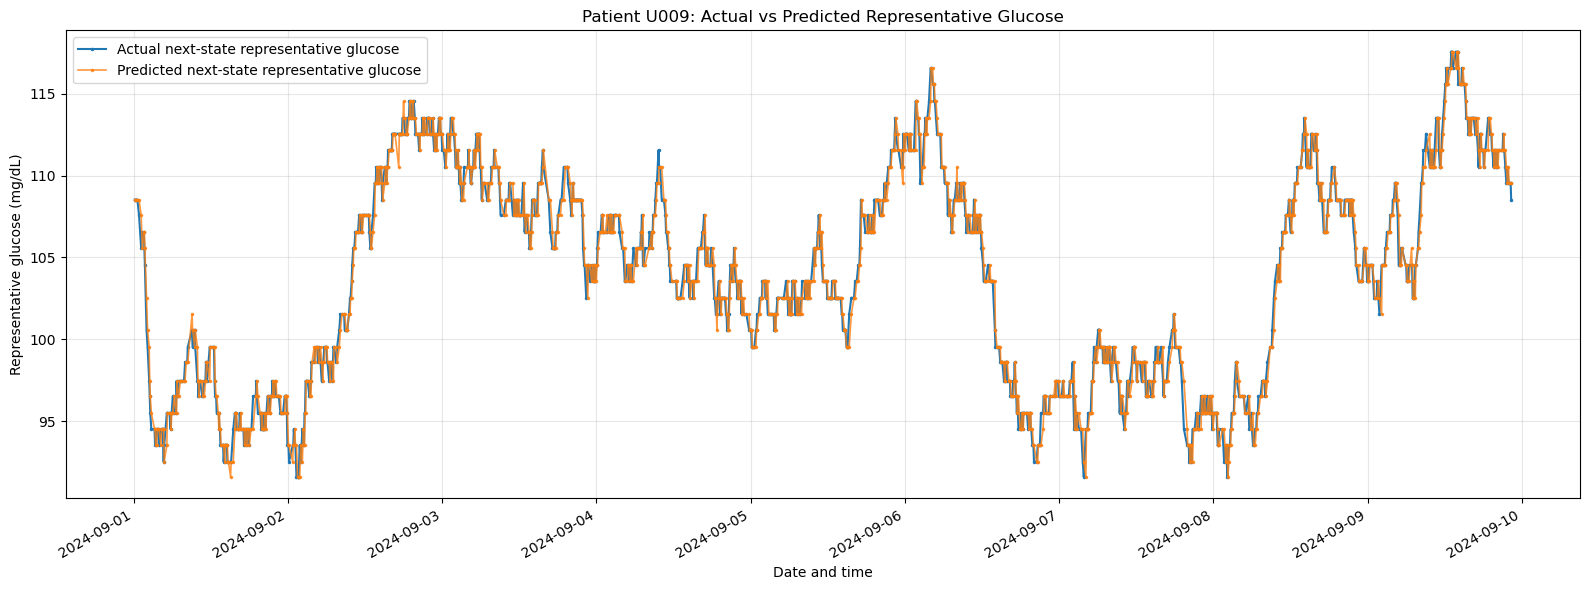

In [29]:
# ============================================================
# 6. GRAPH 1: ACTUAL VS PREDICTED REPRESENTATIVE GLUCOSE
# ============================================================

fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(
    evaluation["Next_Timestamp"],
    evaluation["Actual_Next_Representative_Glucose"],
    label="Actual next-state representative glucose",
    linewidth=1.5,
    marker=".",
    markersize=3
)

ax.plot(
    evaluation["Next_Timestamp"],
    evaluation["Predicted_Glucose"],
    label="Predicted next-state representative glucose",
    linewidth=1.2,
    marker=".",
    markersize=3,
    alpha=0.8
)

ax.set_xlabel("Date and time")
ax.set_ylabel("Representative glucose (mg/dL)")

ax.set_title(
    "Patient U009: Actual vs Predicted Representative Glucose"
)

ax.legend()
ax.grid(alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

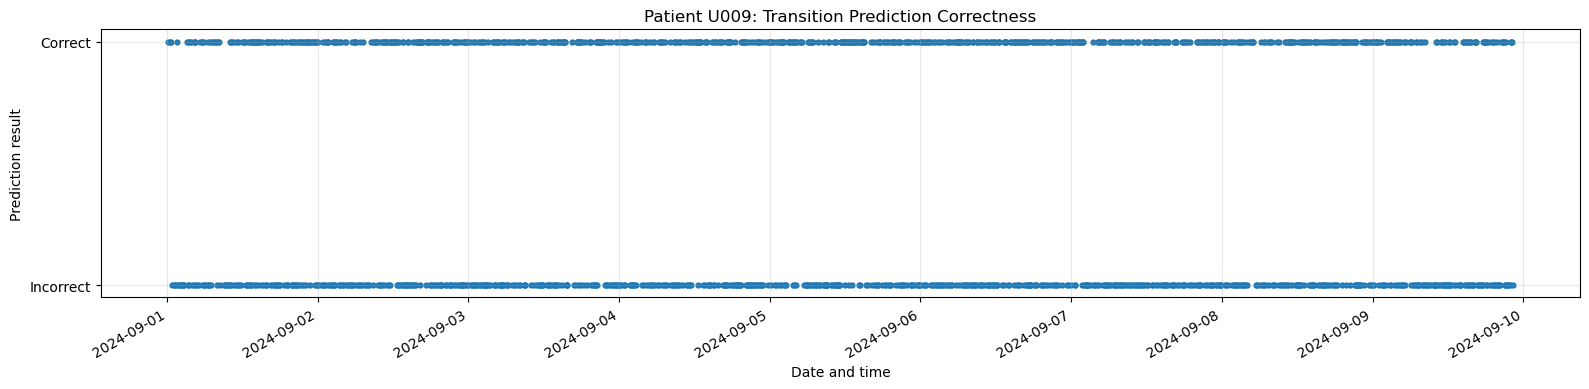

In [30]:
# ============================================================
# 7. GRAPH 2: PREDICTION CORRECTNESS OVER TIME
# ============================================================

fig, ax = plt.subplots(figsize=(16, 4))

ax.scatter(
    evaluation["Next_Timestamp"],
    evaluation["Correct"].astype(int),
    s=12
)

ax.set_yticks(
    [0, 1],
    ["Incorrect", "Correct"]
)

ax.set_xlabel("Date and time")
ax.set_ylabel("Prediction result")

ax.set_title(
    "Patient U009: Transition Prediction Correctness"
)

ax.grid(alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

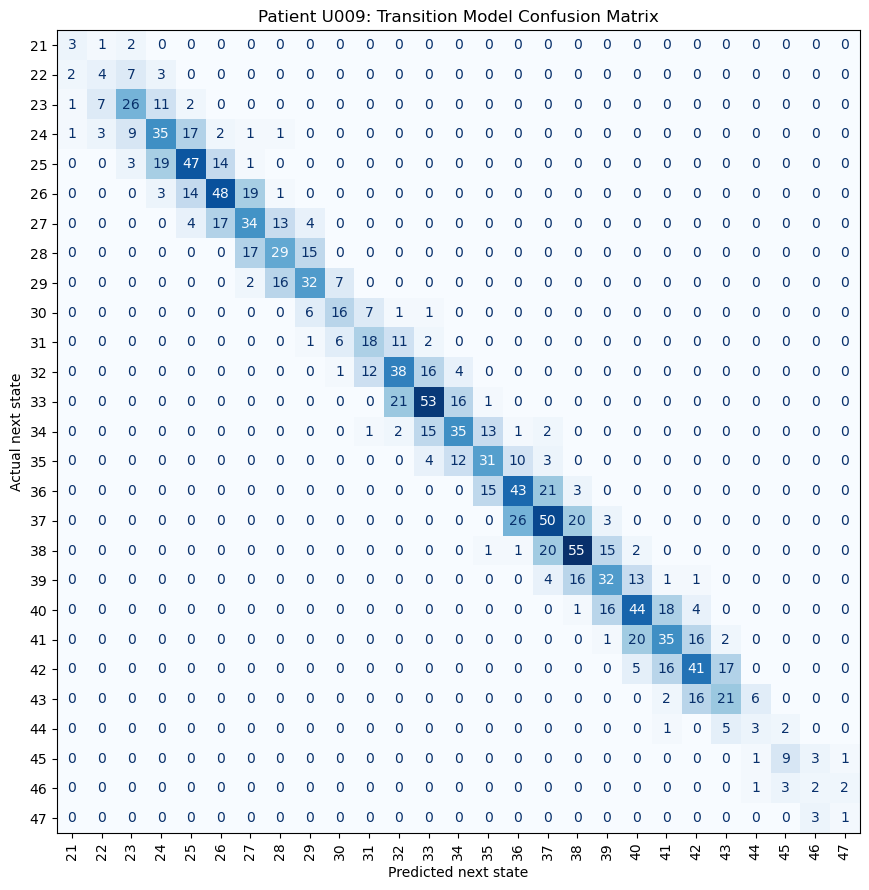

In [31]:
# ============================================================
# 8. GRAPH 3: CONFUSION MATRIX
# ============================================================

labels = sorted(
    set(evaluation["Next_State_ID"]) |
    set(evaluation["Predicted_Next_State"])
)

cm = confusion_matrix(
    evaluation["Next_State_ID"],
    evaluation["Predicted_Next_State"],
    labels=labels
)

fig, ax = plt.subplots(figsize=(10, 9))

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

cm_display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=False
)

ax.set_title(
    "Patient U009: Transition Model Confusion Matrix"
)

ax.set_xlabel("Predicted next state")
ax.set_ylabel("Actual next state")

plt.tight_layout()
plt.show()

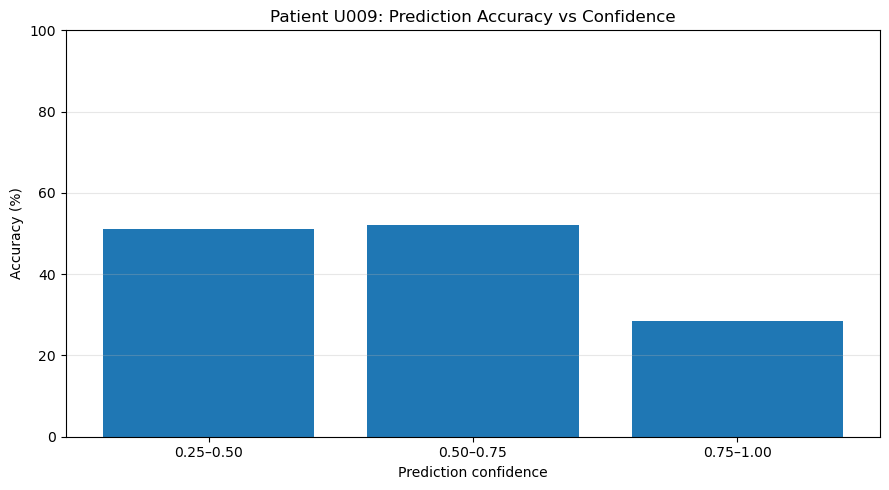


CONFIDENCE ANALYSIS


,Number_of_Predictions,Accuracy
Confidence_Group,,
0–0.25,0,NaN
0.25–0.50,460,51.086957
0.50–0.75,1050,52.190476
0.75–1.00,7,28.571429


In [32]:
# ============================================================
# 9. GRAPH 4: PREDICTION CONFIDENCE VS ACCURACY
# ============================================================

evaluation["Confidence_Group"] = pd.cut(
    evaluation["Prediction_Confidence"],
    bins=[0, 0.25, 0.50, 0.75, 1.000001],
    labels=[
        "0–0.25",
        "0.25–0.50",
        "0.50–0.75",
        "0.75–1.00"
    ],
    include_lowest=True
)

confidence_analysis = (
    evaluation.groupby(
        "Confidence_Group",
        observed=False
    )
    .agg(
        Number_of_Predictions=("Correct", "size"),
        Accuracy=("Correct", "mean")
    )
)

confidence_analysis["Accuracy"] *= 100

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    confidence_analysis.index.astype(str),
    confidence_analysis["Accuracy"]
)

ax.set_xlabel("Prediction confidence")
ax.set_ylabel("Accuracy (%)")

ax.set_title(
    "Patient U009: Prediction Accuracy vs Confidence"
)

ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("\nCONFIDENCE ANALYSIS")
display(confidence_analysis)


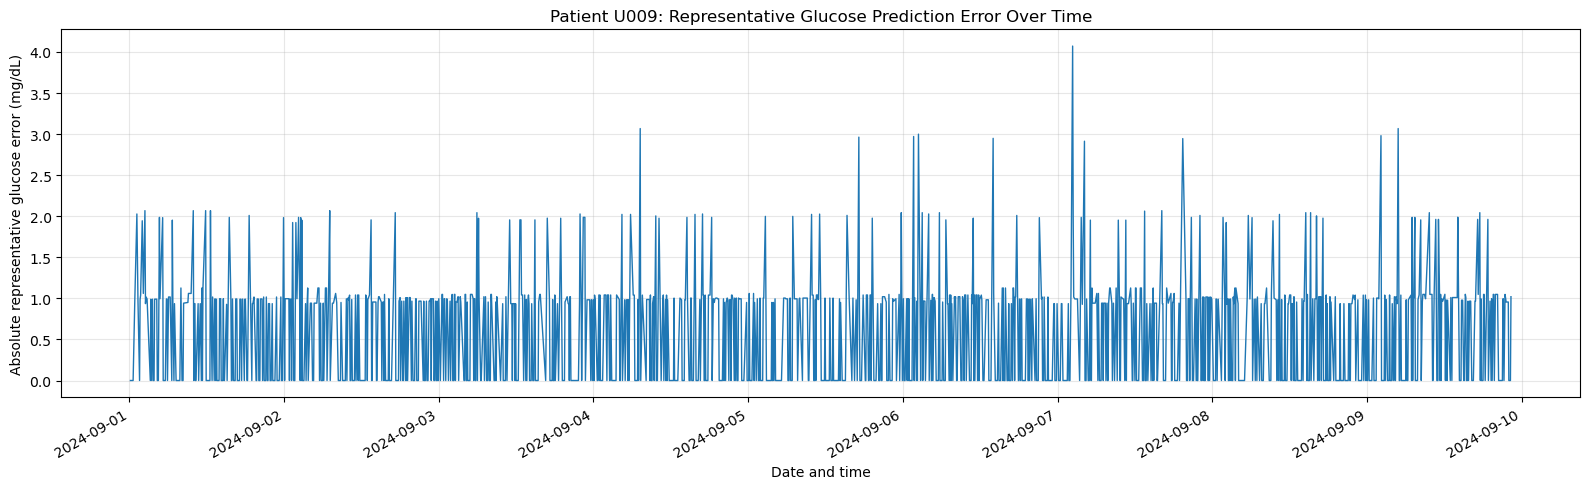

In [33]:
# ============================================================
# 10. GRAPH 5: GLUCOSE PREDICTION ERROR OVER TIME
# ============================================================

evaluation["Absolute_Glucose_Error"] = (
    evaluation["Predicted_Glucose"]
    -
    evaluation["Actual_Next_Representative_Glucose"]
).abs()

fig, ax = plt.subplots(figsize=(16, 5))

ax.plot(
    evaluation["Next_Timestamp"],
    evaluation["Absolute_Glucose_Error"],
    linewidth=1
)

ax.set_xlabel("Date and time")
ax.set_ylabel("Absolute representative glucose error (mg/dL)")

ax.set_title(
    "Patient U009: Representative Glucose Prediction Error Over Time"
)

ax.grid(alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [34]:
# ============================================================
# 11. FINAL PERFORMANCE SUMMARY
# ============================================================

mae = evaluation["Absolute_Glucose_Error"].mean()

print("\n======================================")
print("PATIENT U009 - MODEL PERFORMANCE")
print("======================================")

print("Original filtered test transitions:", total_transitions)
print("Covered transitions:", covered_count)
print("Uncovered transitions:", uncovered_count)

print(f"Model coverage: {coverage_percentage:.2f}%")
print(f"Top-1 accuracy: {accuracy:.2f}%")

print(
    f"Mean absolute representative glucose error: "
    f"{mae:.2f} mg/dL"
)

print(
    "Mean prediction confidence:",
    round(evaluation["Prediction_Confidence"].mean(), 4)
)

print("======================================")



PATIENT U009 - MODEL PERFORMANCE
Original filtered test transitions: 1569
Covered transitions: 1517
Uncovered transitions: 52
Model coverage: 96.69%
Top-1 accuracy: 51.75%
Mean absolute representative glucose error: 0.55 mg/dL
Mean prediction confidence: 0.5274


In [35]:
# ============================================================
# 12. SAVE PATIENT U009 EVALUATION RESULTS
# ============================================================

evaluation.to_csv(
    "U009_transition_model_evaluation.csv",
    index=False
)

print("\nEvaluation results saved.")


Evaluation results saved.


In [36]:
# ============================================================
# 1. SELECT TEST PATIENT U010
# ============================================================

PATIENT_ID = "U010"

# Use filtered test transitions to remain consistent
# with the state filtering performed earlier.

evaluation = filtered_test_transitions[
    filtered_test_transitions["user_id"] == PATIENT_ID
].copy()

if evaluation.empty:
    raise ValueError(
        f"Patient {PATIENT_ID} was not found in filtered_test_transitions."
    )

evaluation["timestamp"] = pd.to_datetime(
    evaluation["timestamp"]
)

evaluation["Next_Timestamp"] = pd.to_datetime(
    evaluation["Next_Timestamp"]
)

evaluation = evaluation.sort_values("Next_Timestamp").copy()

print("Selected patient:", PATIENT_ID)
print("Filtered test transitions:", len(evaluation))


# ============================================================
# 2. PREDICT NEXT STATE USING THE TRAINING TRANSITION MODEL
# ============================================================

predicted_states = []
prediction_probabilities = []

for _, row in evaluation.iterrows():

    current_state = int(row["State_ID"])
    actual_action = int(row["Action_ID"])

    # Find the training-based transition probabilities
    # for this current state and recorded insulin action.

    matching = transition_counts[
        (transition_counts["State_ID"] == current_state) &
        (transition_counts["Action_ID"] == actual_action)
    ]

    if matching.empty:

        predicted_states.append(np.nan)
        prediction_probabilities.append(np.nan)

        continue

    # Select the most probable next state.

    best_row = matching.loc[
        matching["Probability"].idxmax()
    ]

    predicted_states.append(
        int(best_row["Next_State_ID"])
    )

    prediction_probabilities.append(
        float(best_row["Probability"])
    )


evaluation["Predicted_Next_State"] = predicted_states

evaluation["Prediction_Confidence"] = (
    prediction_probabilities
)


# ============================================================
# 3. CHECK MODEL COVERAGE
# ============================================================

total_transitions = len(evaluation)

covered_mask = evaluation["Predicted_Next_State"].notna()

covered_count = int(covered_mask.sum())

uncovered_count = total_transitions - covered_count

coverage_percentage = (
    100 * covered_count / total_transitions
    if total_transitions > 0 else 0
)

print("\nMODEL COVERAGE")
print("-----------------------")

print("Total test transitions:", total_transitions)
print("Covered transitions:", covered_count)
print("Uncovered transitions:", uncovered_count)

print(
    f"Model coverage: {coverage_percentage:.2f}%"
)

if covered_count == 0:
    raise ValueError(
        "The training transition model does not cover any "
        "state-action pairs for this patient."
    )


# Retain only transitions for which the model
# has an empirical prediction.

evaluation = evaluation.loc[covered_mask].copy()

evaluation["Predicted_Next_State"] = (
    evaluation["Predicted_Next_State"].astype(int)
)


# ============================================================
# 4. COMPARE PREDICTED AND ACTUAL NEXT STATES
# ============================================================

evaluation["Correct"] = (
    evaluation["Predicted_Next_State"]
    == evaluation["Next_State_ID"]
)

# Convert discrete state IDs into representative glucose values.

evaluation["Predicted_Glucose"] = (
    evaluation["Predicted_Next_State"].map(glucose_lookup)
)

evaluation["Actual_Next_Representative_Glucose"] = (
    evaluation["Next_State_ID"].map(glucose_lookup)
)

accuracy = evaluation["Correct"].mean() * 100

print("\nPREDICTION PERFORMANCE")
print("-----------------------")

print("Covered test transitions:", len(evaluation))

print(
    f"Top-1 accuracy: {accuracy:.2f}%"
)


# ============================================================
# 5. INSPECT THE OBSERVATION PERIOD
# ============================================================

print("\nOBSERVATION PERIOD")

print(
    "Start:",
    evaluation["Next_Timestamp"].min()
)

print(
    "End:",
    evaluation["Next_Timestamp"].max()
)

print(
    "Number of unique timestamps:",
    evaluation["Next_Timestamp"].nunique()
)

Selected patient: U010
Filtered test transitions: 1539

MODEL COVERAGE
-----------------------
Total test transitions: 1539
Covered transitions: 1482
Uncovered transitions: 57
Model coverage: 96.30%

PREDICTION PERFORMANCE
-----------------------
Covered test transitions: 1482
Top-1 accuracy: 53.44%

OBSERVATION PERIOD
Start: 2024-09-01 00:10:00
End: 2024-09-09 22:20:00
Number of unique timestamps: 1482


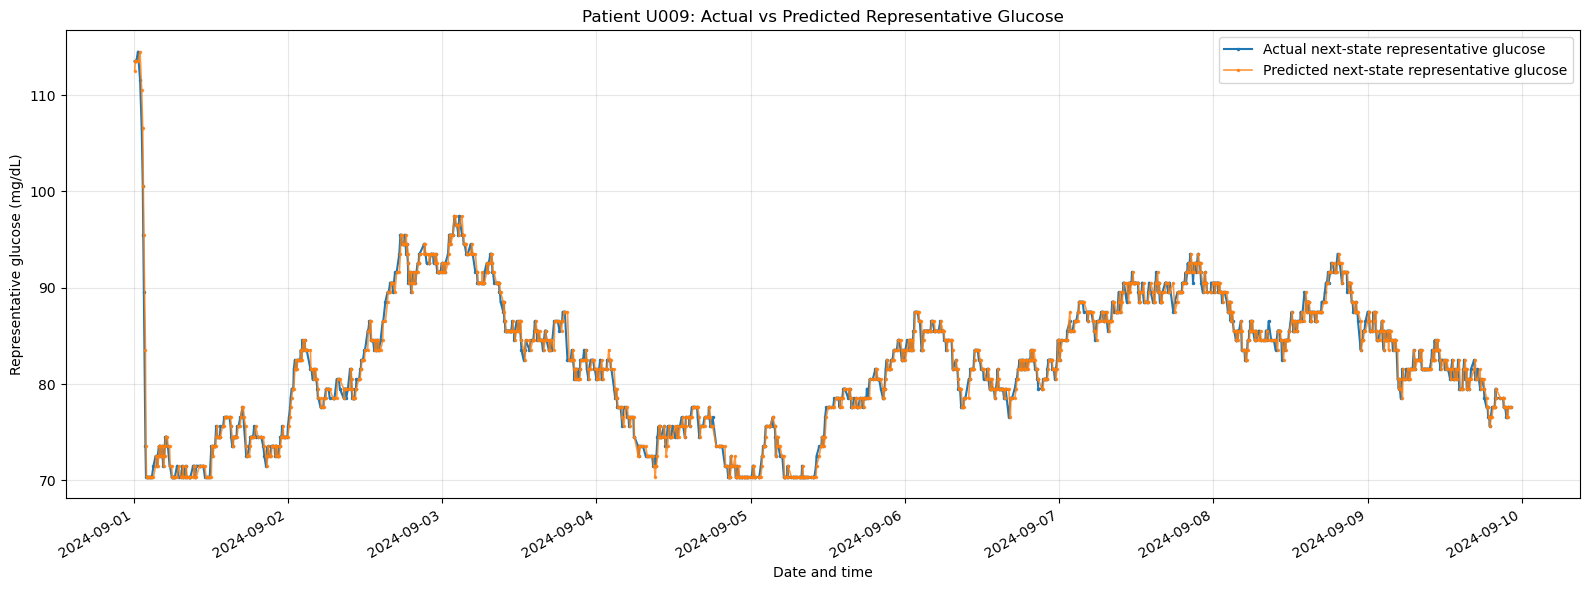

In [37]:
# ============================================================
# 6. GRAPH 1: ACTUAL VS PREDICTED REPRESENTATIVE GLUCOSE
# ============================================================

fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(
    evaluation["Next_Timestamp"],
    evaluation["Actual_Next_Representative_Glucose"],
    label="Actual next-state representative glucose",
    linewidth=1.5,
    marker=".",
    markersize=3
)

ax.plot(
    evaluation["Next_Timestamp"],
    evaluation["Predicted_Glucose"],
    label="Predicted next-state representative glucose",
    linewidth=1.2,
    marker=".",
    markersize=3,
    alpha=0.8
)

ax.set_xlabel("Date and time")
ax.set_ylabel("Representative glucose (mg/dL)")

ax.set_title(
    "Patient U009: Actual vs Predicted Representative Glucose"
)

ax.legend()
ax.grid(alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

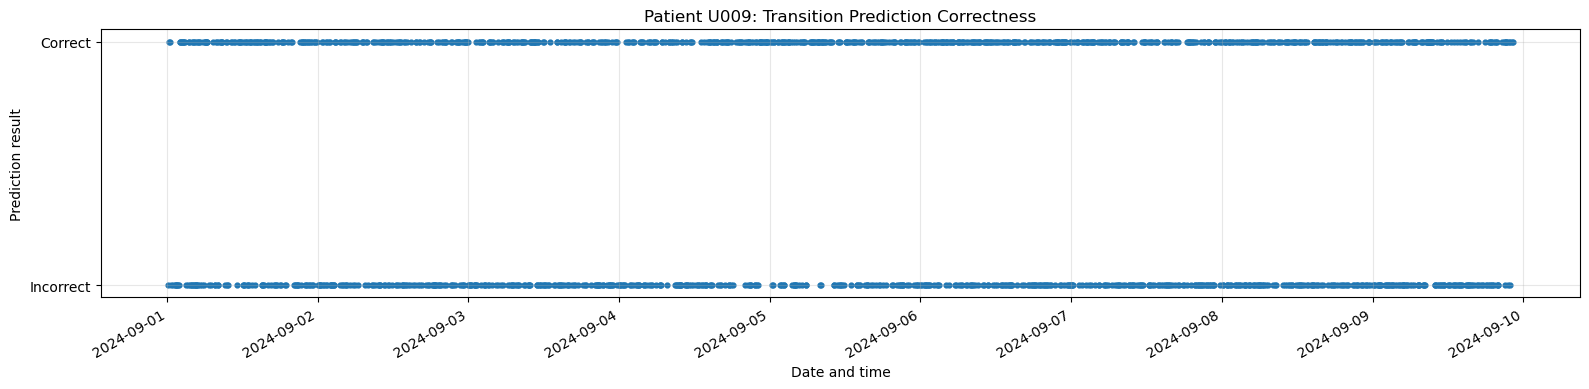

In [38]:
# ============================================================
# 7. GRAPH 2: PREDICTION CORRECTNESS OVER TIME
# ============================================================

fig, ax = plt.subplots(figsize=(16, 4))

ax.scatter(
    evaluation["Next_Timestamp"],
    evaluation["Correct"].astype(int),
    s=12
)

ax.set_yticks(
    [0, 1],
    ["Incorrect", "Correct"]
)

ax.set_xlabel("Date and time")
ax.set_ylabel("Prediction result")

ax.set_title(
    "Patient U009: Transition Prediction Correctness"
)

ax.grid(alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()



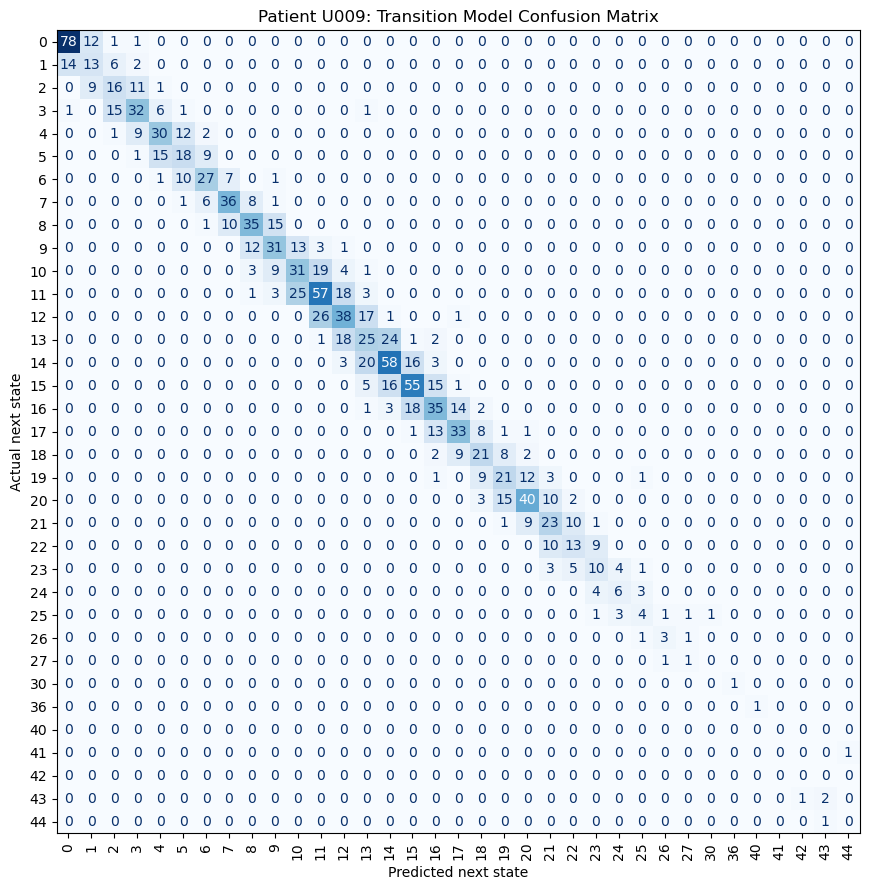

In [39]:
# ============================================================
# 8. GRAPH 3: CONFUSION MATRIX
# ============================================================

labels = sorted(
    set(evaluation["Next_State_ID"]) |
    set(evaluation["Predicted_Next_State"])
)

cm = confusion_matrix(
    evaluation["Next_State_ID"],
    evaluation["Predicted_Next_State"],
    labels=labels
)

fig, ax = plt.subplots(figsize=(10, 9))

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

cm_display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=False
)

ax.set_title(
    "Patient U009: Transition Model Confusion Matrix"
)

ax.set_xlabel("Predicted next state")
ax.set_ylabel("Actual next state")

plt.tight_layout()
plt.show()

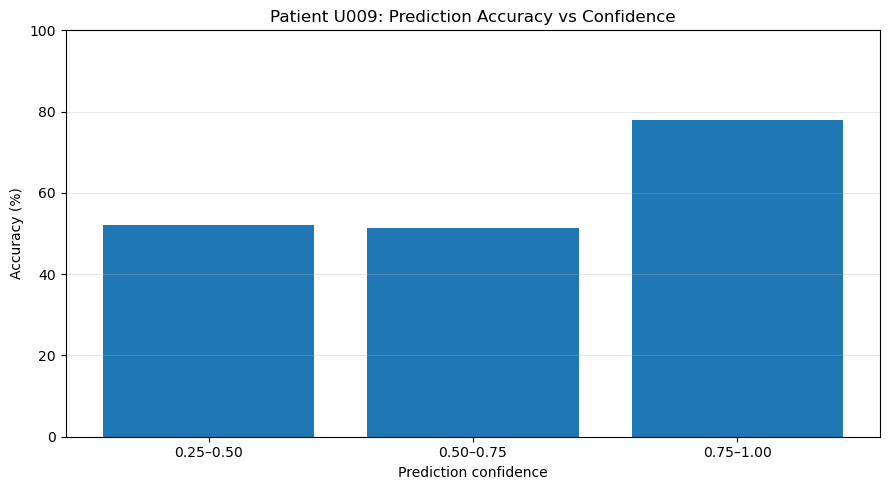


CONFIDENCE ANALYSIS


,Number_of_Predictions,Accuracy
Confidence_Group,,
0–0.25,0,NaN
0.25–0.50,431,52.204176
0.50–0.75,947,51.319958
0.75–1.00,104,77.884615


In [40]:
# ============================================================
# 9. GRAPH 4: PREDICTION CONFIDENCE VS ACCURACY
# ============================================================

evaluation["Confidence_Group"] = pd.cut(
    evaluation["Prediction_Confidence"],
    bins=[0, 0.25, 0.50, 0.75, 1.000001],
    labels=[
        "0–0.25",
        "0.25–0.50",
        "0.50–0.75",
        "0.75–1.00"
    ],
    include_lowest=True
)

confidence_analysis = (
    evaluation.groupby(
        "Confidence_Group",
        observed=False
    )
    .agg(
        Number_of_Predictions=("Correct", "size"),
        Accuracy=("Correct", "mean")
    )
)

confidence_analysis["Accuracy"] *= 100

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    confidence_analysis.index.astype(str),
    confidence_analysis["Accuracy"]
)

ax.set_xlabel("Prediction confidence")
ax.set_ylabel("Accuracy (%)")

ax.set_title(
    "Patient U009: Prediction Accuracy vs Confidence"
)

ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("\nCONFIDENCE ANALYSIS")
display(confidence_analysis)


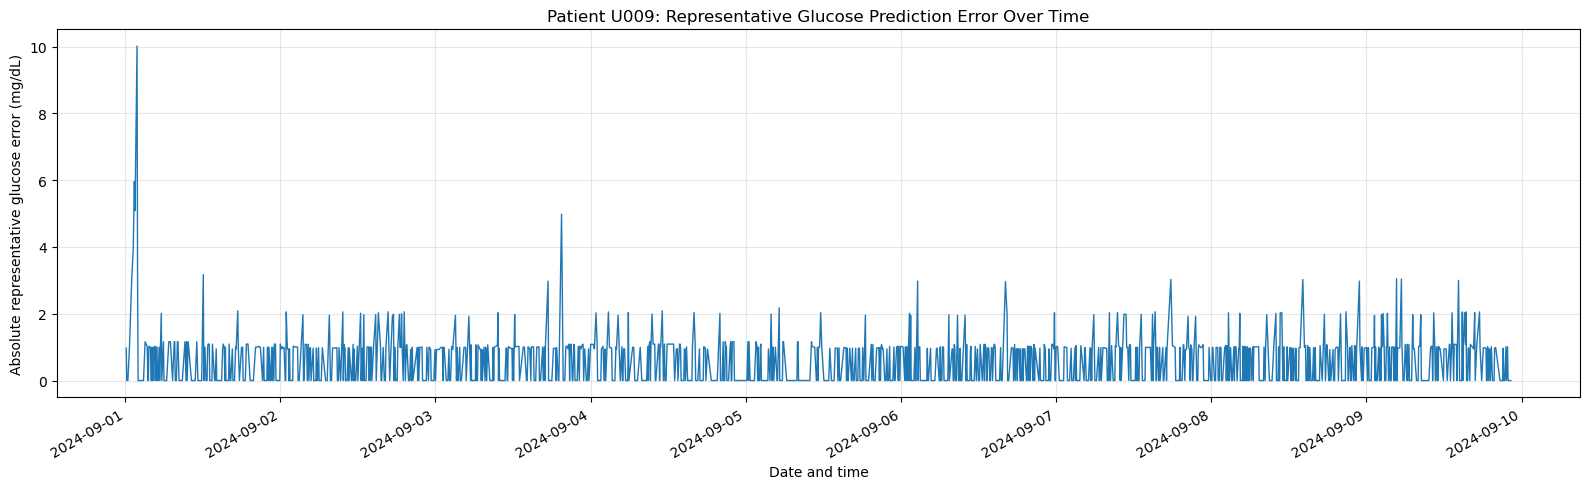

In [41]:
# ============================================================
# 10. GRAPH 5: GLUCOSE PREDICTION ERROR OVER TIME
# ============================================================

evaluation["Absolute_Glucose_Error"] = (
    evaluation["Predicted_Glucose"]
    -
    evaluation["Actual_Next_Representative_Glucose"]
).abs()

fig, ax = plt.subplots(figsize=(16, 5))

ax.plot(
    evaluation["Next_Timestamp"],
    evaluation["Absolute_Glucose_Error"],
    linewidth=1
)

ax.set_xlabel("Date and time")
ax.set_ylabel("Absolute representative glucose error (mg/dL)")

ax.set_title(
    "Patient U009: Representative Glucose Prediction Error Over Time"
)

ax.grid(alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [42]:
# ============================================================
# 11. FINAL PERFORMANCE SUMMARY
# ============================================================

mae = evaluation["Absolute_Glucose_Error"].mean()

print("\n======================================")
print("PATIENT U010 - MODEL PERFORMANCE")
print("======================================")

print("Original filtered test transitions:", total_transitions)
print("Covered transitions:", covered_count)
print("Uncovered transitions:", uncovered_count)

print(f"Model coverage: {coverage_percentage:.2f}%")
print(f"Top-1 accuracy: {accuracy:.2f}%")

print(
    f"Mean absolute representative glucose error: "
    f"{mae:.2f} mg/dL"
)

print(
    "Mean prediction confidence:",
    round(evaluation["Prediction_Confidence"].mean(), 4)
)

print("======================================")


# ============================================================
# 12. SAVE PATIENT U010 EVALUATION RESULTS
# ============================================================

evaluation.to_csv(
    "U010_transition_model_evaluation.csv",
    index=False
)

print("\nEvaluation results saved.")



PATIENT U010 - MODEL PERFORMANCE
Original filtered test transitions: 1539
Covered transitions: 1482
Uncovered transitions: 57
Model coverage: 96.30%
Top-1 accuracy: 53.44%
Mean absolute representative glucose error: 0.55 mg/dL
Mean prediction confidence: 0.5578

Evaluation results saved.


In [43]:
# ============================================================
# GLUCOSE-BASED REWARD FUNCTION
# ============================================================
# --------------------------------------------------
# 1. DEFINE REWARD FUNCTION PARAMETERS
# --------------------------------------------------

G_IDEAL = 110

G_LOW = 70
G_HIGH = 180

SIGMA_L = 20
SIGMA_R = 35

LAMBDA_L = 1
LAMBDA_R = 1


# --------------------------------------------------
# 2. VALIDATE PARAMETERS
# --------------------------------------------------

if not (G_LOW < G_IDEAL < G_HIGH):
    raise ValueError(
        "Glucose thresholds must satisfy "
        "G_LOW < G_IDEAL < G_HIGH."
    )

if SIGMA_L <= 0 or SIGMA_R <= 0:
    raise ValueError("Sigma values must be positive.")

if LAMBDA_L < 0 or LAMBDA_R < 0:
    raise ValueError("Penalty coefficients cannot be negative.")


# --------------------------------------------------
# 3. DEFINE THE REWARD FUNCTION
# --------------------------------------------------

def glucose_reward(g):

    if pd.isna(g):
        raise ValueError(
            "Representative glucose is missing."
        )

    # Region 1: Glucose below the lower threshold.
    # Quadratic penalty.

    if g < G_LOW:

        return -LAMBDA_L * (
            (G_LOW - g) / (G_IDEAL - G_LOW)
        )**2


    # Region 2: Glucose between the lower threshold
    # and the ideal glucose value.

    elif g <= G_IDEAL:

        boundary_L = np.exp(
            -((G_LOW - G_IDEAL)**2)
            / (2 * SIGMA_L**2)
        )

        return (
            np.exp(
                -((g - G_IDEAL)**2)
                / (2 * SIGMA_L**2)
            )
            - boundary_L
        ) / (1 - boundary_L)


    # Region 3: Glucose between the ideal value
    # and the upper threshold.

    elif g <= G_HIGH:

        boundary_R = np.exp(
            -((G_HIGH - G_IDEAL)**2)
            / (2 * SIGMA_R**2)
        )

        return (
            np.exp(
                -((g - G_IDEAL)**2)
                / (2 * SIGMA_R**2)
            )
            - boundary_R
        ) / (1 - boundary_R)


    # Region 4: Glucose above the upper threshold.
    # Quadratic penalty.

    else:

        return -LAMBDA_R * (
            (g - G_HIGH) / (G_HIGH - G_IDEAL)
        )**2


print("Glucose reward function defined successfully.")


Glucose reward function defined successfully.


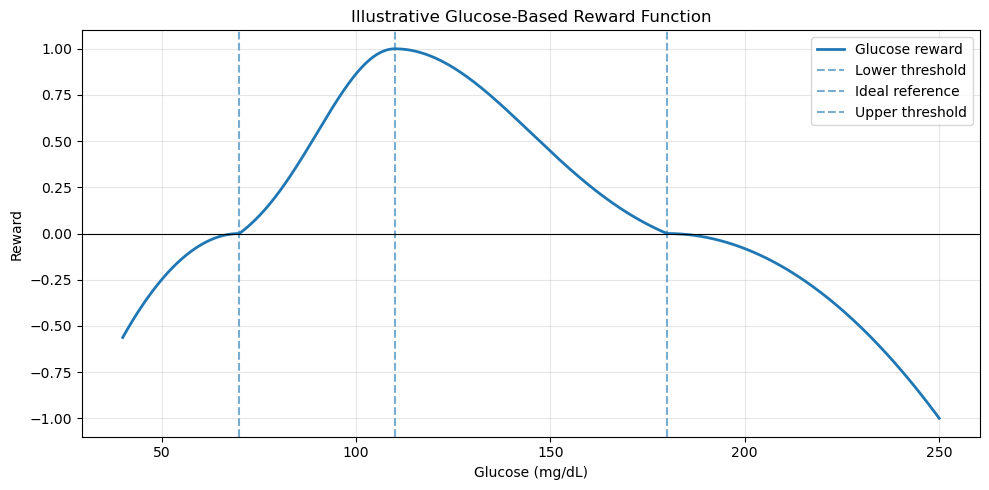

In [44]:
# ============================================================
# PLOT THE GLUCOSE REWARD FUNCTION
# ============================================================

glucose_values = np.linspace(40, 250, 500)

rewards = [
    glucose_reward(g)
    for g in glucose_values
]

plt.figure(figsize=(10, 5))

plt.plot(
    glucose_values,
    rewards,
    linewidth=2,
    label="Glucose reward"
)

plt.axvline(G_LOW, linestyle="--", alpha=0.6, label="Lower threshold")
plt.axvline(G_IDEAL, linestyle="--", alpha=0.6, label="Ideal reference")
plt.axvline(G_HIGH, linestyle="--", alpha=0.6, label="Upper threshold")

plt.axhline(0, color="black", linewidth=0.8)

plt.xlabel("Glucose (mg/dL)")
plt.ylabel("Reward")

plt.title("Illustrative Glucose-Based Reward Function")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [45]:
# ==========================================
# CELL 7A: ENVIRONMENT SETUP
# ==========================================

# ------------------------------------------
# 1. INITIALISE RANDOM NUMBER GENERATOR
# ------------------------------------------

rng = np.random.default_rng(42)


# ------------------------------------------
# 2. REPRESENTATIVE GLUCOSE AND INSULIN VALUES
# ------------------------------------------

glucose_lookup = (
    representative_glucose_levels
    .set_index("State_ID")["Representative_Glucose"]
    .to_dict()
)

insulin_lookup = (
    representative_insulin_levels
    .set_index("Action_ID")["Representative_Insulin"]
    .to_dict()
)


# ------------------------------------------
# 3. IDENTIFY STATES FROM THE TRANSITION MODEL
# ------------------------------------------

observed_states = (
    set(transition_counts["State_ID"].astype(int))
    |
    set(transition_counts["Next_State_ID"].astype(int))
)

state_ids = sorted(observed_states)


# ------------------------------------------
# 4. IDENTIFY SUPPORTED ACTIONS
# ------------------------------------------

action_ids = sorted(
    transition_counts["Action_ID"]
    .astype(int)
    .unique()
)

missing_glucose = [
    state for state in state_ids
    if state not in glucose_lookup
    or pd.isna(glucose_lookup[state])
]

missing_insulin = [
    action for action in action_ids
    if action not in insulin_lookup
    or pd.isna(insulin_lookup[action])
]

if missing_glucose:
    raise ValueError(
        f"Missing representative glucose values: {missing_glucose}"
    )

if missing_insulin:
    raise ValueError(
        f"Missing representative insulin values: {missing_insulin}"
    )


# ------------------------------------------
# 5. INITIAL-STATE DISTRIBUTION
# ------------------------------------------

initial_state_counts = (
    filtered_transitions["State_ID"]
    .value_counts()
    .reindex(state_ids, fill_value=0)
)

if initial_state_counts.sum() == 0:
    raise ValueError(
        "No training transitions available to initialise the environment."
    )

initial_state_probs = (
    initial_state_counts / initial_state_counts.sum()
).to_numpy(dtype=float)


# ==========================================
# 6. DEFINE THE ENVIRONMENT
# ==========================================

class DiabetesEnvironment:

    def __init__(
        self,
        transition_counts,
        glucose_lookup,
        initial_state_probs,
        rng,
        state_ids
    ):

        self.state_ids = list(state_ids)

        self._glucose_lookup = glucose_lookup

        self._initial_state_probs = np.asarray(
            initial_state_probs,
            dtype=float
        )

        self._rng = rng


        # --------------------------------------
        # Validate initial-state distribution
        # --------------------------------------

        if (
            len(self._initial_state_probs) != len(self.state_ids)
            or not np.all(np.isfinite(self._initial_state_probs))
            or np.any(self._initial_state_probs < 0)
            or not np.isclose(self._initial_state_probs.sum(), 1.0)
        ):

            raise ValueError(
                "The initial-state probabilities are invalid."
            )


        # --------------------------------------
        # Build private transition model
        # --------------------------------------

        self._transition_probs = {}

        for (state, action), group in transition_counts.groupby(
            ["State_ID", "Action_ID"]
        ):

            state = int(state)
            action = int(action)

            next_states = group[
                "Next_State_ID"
            ].to_numpy(dtype=int)

            probs = group[
                "Probability"
            ].to_numpy(dtype=float)


            if (
                len(next_states) == 0
                or not np.all(np.isfinite(probs))
                or np.any(probs < 0)
                or not np.isclose(probs.sum(), 1.0)
            ):

                raise ValueError(
                    f"Invalid transition probabilities for "
                    f"state {state}, action {action}."
                )



            if state not in self.state_ids:

                raise ValueError(
                    f"Unknown state ID: {state}"
                )


            if not np.all(
                np.isin(next_states, self.state_ids)
            ):

                raise ValueError(
                    f"Unknown next-state ID for "
                    f"state {state}, action {action}."
                )


            self._transition_probs[(state, action)] = (
                next_states,
                probs
            )


        # --------------------------------------
        # Build available actions for each state
        # --------------------------------------

        self._available_actions = {
            state: [] for state in self.state_ids
        }

        for state, action in self._transition_probs:

            self._available_actions[state].append(action)


        for state in self._available_actions:

            self._available_actions[state] = sorted(
                set(self._available_actions[state])
            )


        # --------------------------------------
        # Identify states without available actions
        # --------------------------------------

        self._states_without_actions = [
            state
            for state in self.state_ids
            if len(self._available_actions[state]) == 0
        ]


        # --------------------------------------
        # Exclude states without actions from
        # the initial-state distribution
        # --------------------------------------

        valid_initial_mask = np.array([
            len(self._available_actions[state]) > 0
            for state in self.state_ids
        ])

        self._initial_state_probs *= valid_initial_mask

        if self._initial_state_probs.sum() <= 0:

            raise ValueError(
                "No initial states have supported actions."
            )

        self._initial_state_probs /= (
            self._initial_state_probs.sum()
        )

        self.state = None


    # --------------------------------------
    # START A NEW EPISODE
    # --------------------------------------

    def reset(self):

        self.state = int(
            self._rng.choice(
                self.state_ids,
                p=self._initial_state_probs
            )
        )

        return self.state


    # --------------------------------------
    # RETURN AVAILABLE ACTIONS
    # --------------------------------------

    def available_actions(self, state):

        return self._available_actions.get(
            int(state),
            []
        )


    # --------------------------------------
    # TAKE AN ACTION AND OBSERVE THE OUTCOME
    # --------------------------------------

    def step(self, action):

        if self.state is None:

            raise RuntimeError(
                "Call env.reset() before taking an action."
            )

        state = self.state

        action = int(action)

        key = (state, action)

        if key not in self._transition_probs:

            raise ValueError(
                f"Action {action} has no observed transitions "
                f"for state {state}."
            )


        # ----------------------------------
        # Sample next state internally
        # ----------------------------------

        next_states, probs = self._transition_probs[key]

        next_state = int(
            self._rng.choice(
                next_states,
                p=probs
            )
        )


        # ----------------------------------
        # Calculate reward from resulting state
        # ----------------------------------

        next_glucose = self._glucose_lookup[next_state]

        reward = glucose_reward(next_glucose)


        self.state = next_state

        done = False

        info = {}

        return next_state, reward, done, info


# ==========================================
# 7. CREATE THE ENVIRONMENT
# ==========================================

env = DiabetesEnvironment(
    transition_counts=transition_counts,
    glucose_lookup=glucose_lookup,
    initial_state_probs=initial_state_probs,
    rng=rng,
    state_ids=state_ids
)


print("Environment created successfully!")

print("Number of states:", len(state_ids))

print("Number of supported actions:", len(action_ids))

print(
    "States without available actions:",
    env._states_without_actions
)


# ==========================================
# 8. DISPLAY AVAILABLE ACTIONS
# ==========================================

print("\nActions supported in each state:")

for state in state_ids:

    print(
        f"State {state} "
        f"(glucose ≈ {glucose_lookup[state]:.2f}):",
        env.available_actions(state)
    )


# ==========================================
# 9. TEST RESET AND ONE ENVIRONMENT INTERACTION
# ==========================================

test_state = env.reset()

print("\nTest initial state:", test_state)

test_actions = env.available_actions(test_state)

if test_actions:

    test_action = test_actions[0]

    test_next_state, test_reward, test_done, test_info = (
        env.step(test_action)
    )

    print("Test action:", test_action)

    print("Observed next state:", test_next_state)

    print("Observed reward:", round(test_reward, 4))

    print("Episode finished:", test_done)

    print("Additional information:", test_info)

else:

    print("This initial state has no supported actions.")

Environment created successfully!
Number of states: 118
Number of supported actions: 27
States without available actions: []

Actions supported in each state:
State 0 (glucose ≈ 70.36): [0, 7, 9, 11, 12, 15]
State 1 (glucose ≈ 71.52): [0, 9, 13, 16, 19, 20, 25, 27]
State 2 (glucose ≈ 72.54): [0, 6, 14, 26]
State 3 (glucose ≈ 73.53): [0, 7, 9, 10, 13, 15, 16, 18, 21, 22, 27]
State 4 (glucose ≈ 74.53): [0, 11, 15, 20]
State 5 (glucose ≈ 75.62): [0, 7]
State 6 (glucose ≈ 76.57): [0, 4, 12, 15, 19]
State 7 (glucose ≈ 77.58): [0, 7, 10, 11, 13, 14, 17, 18, 23]
State 8 (glucose ≈ 78.54): [0, 7, 9, 11, 19]
State 9 (glucose ≈ 79.53): [0, 6, 7, 10, 11, 16, 20, 21, 24, 26]
State 10 (glucose ≈ 80.50): [0, 4, 7, 18, 24]
State 11 (glucose ≈ 81.58): [0, 6, 8, 12, 14, 17]
State 12 (glucose ≈ 82.53): [0, 6, 14, 18, 19, 24, 27]
State 13 (glucose ≈ 83.55): [0, 8, 17, 19, 23, 24]
State 14 (glucose ≈ 84.55): [0, 6, 10, 11, 17, 19]
State 15 (glucose ≈ 85.56): [0, 8, 11, 15, 18, 19]
State 16 (glucose ≈ 86.5

In [46]:
# ==========================================
# CELL 7B: THEORETICAL OPTIMAL Q-TABLE
# Bellman Value Iteration
# ==========================================

# ------------------------------------------
# 1. DISCOUNT FACTOR AND CONVERGENCE SETTINGS
# ------------------------------------------

gamma = 0.9

tolerance = 1e-8

max_iterations = 100000

if not (0 <= gamma < 1):
    raise ValueError(
        "Gamma must satisfy 0 <= gamma < 1."
    )


# ------------------------------------------
# 2. IDENTIFY STATES AND ACTIONS
# ------------------------------------------

state_ids = sorted(
    set(transition_counts["State_ID"].astype(int))
    |
    set(transition_counts["Next_State_ID"].astype(int))
)

action_ids = sorted(
    transition_counts["Action_ID"]
    .astype(int)
    .unique()
)

n_states = len(state_ids)
n_actions = len(action_ids)

state_to_idx = {
    state: idx
    for idx, state in enumerate(state_ids)
}

action_to_idx = {
    action: idx
    for idx, action in enumerate(action_ids)
}

print("Number of states:", n_states)
print("Number of supported actions:", n_actions)


# ------------------------------------------
# 3. CHECK REPRESENTATIVE VALUE LOOKUPS
# ------------------------------------------

missing_glucose_states = [
    s for s in state_ids
    if s not in glucose_lookup
]

missing_insulin_actions = [
    a for a in action_ids
    if a not in insulin_lookup
]

if missing_glucose_states:
    raise ValueError(
        f"Missing glucose values: {missing_glucose_states}"
    )

if missing_insulin_actions:
    raise ValueError(
        f"Missing insulin values: {missing_insulin_actions}"
    )


# ------------------------------------------
# 4. BUILD TRANSITION PROBABILITY MATRIX
# ------------------------------------------

# P[s, a, s_next] = P(s_next | s, a)

P = np.zeros(
    (n_states, n_actions, n_states)
)

valid_actions = {
    state: [] for state in state_ids
}


for (state, action), group in transition_counts.groupby(
    ["State_ID", "Action_ID"]
):

    state = int(state)
    action = int(action)

    s_idx = state_to_idx[state]
    a_idx = action_to_idx[action]

    for _, row in group.iterrows():

        next_state = int(row["Next_State_ID"])

        next_idx = state_to_idx[next_state]

        P[s_idx, a_idx, next_idx] = float(
            row["Probability"]
        )

    valid_actions[state].append(action)


# Remove duplicate actions and sort.

for state in valid_actions:

    valid_actions[state] = sorted(
        set(valid_actions[state])
    )


# ------------------------------------------
# 5. VALIDATE TRANSITION PROBABILITIES
# ------------------------------------------

for state in state_ids:

    s_idx = state_to_idx[state]

    for action in valid_actions[state]:

        a_idx = action_to_idx[action]

        probability_sum = P[
            s_idx, a_idx, :
        ].sum()

        if not np.isclose(probability_sum, 1.0):

            raise ValueError(
                f"Transition probabilities do not sum to 1 "
                f"for State_ID={state}, Action_ID={action}. "
                f"Sum = {probability_sum}"
            )


print("\nTransition probability matrix validated.")


# ------------------------------------------
# 6. REWARD ASSOCIATED WITH EACH NEXT STATE
# ------------------------------------------

# Reward is determined by the representative glucose
# value of the resulting state.

rewards = np.array([
    glucose_reward(glucose_lookup[state])
    for state in state_ids
], dtype=float)

if not np.all(np.isfinite(rewards)):
    raise ValueError("Invalid reward values found.")


# ------------------------------------------
# 7. BELLMAN VALUE ITERATION
# ------------------------------------------

V = np.zeros(n_states)

converged = False

for iteration in range(max_iterations):

    V_new = V.copy()

    for state in state_ids:

        s_idx = state_to_idx[state]

        if not valid_actions[state]:
            continue

        action_values = []

        for action in valid_actions[state]:

            a_idx = action_to_idx[action]

            q_value = np.sum(
                P[s_idx, a_idx, :]
                *
                (rewards + gamma * V)
            )

            action_values.append(q_value)

        V_new[s_idx] = max(action_values)

    difference = np.max(
        np.abs(V_new - V)
    )

    V = V_new

    if difference < tolerance:

        converged = True
        break


if not converged:

    raise RuntimeError(
        "Value iteration did not converge within "
        f"{max_iterations} iterations."
    )


print("\nVALUE ITERATION RESULTS")
print("-----------------------")
print("Converged:", converged)
print("Iterations:", iteration + 1)
print("Final maximum difference:", difference)


# ------------------------------------------
# 8. CALCULATE FINAL OPTIMAL Q-TABLE
# ------------------------------------------

Q_optimal = np.full(
    (n_states, n_actions),
    np.nan
)

for state in state_ids:

    s_idx = state_to_idx[state]

    for action in valid_actions[state]:

        a_idx = action_to_idx[action]

        Q_optimal[s_idx, a_idx] = np.sum(
            P[s_idx, a_idx, :]
            *
            (rewards + gamma * V)
        )


# ------------------------------------------
# 9. DISPLAY AND SAVE THEORETICAL Q-TABLE
# ------------------------------------------

state_labels = [
    f"State_ID={s} | Glucose={glucose_lookup[s]:.2f}"
    for s in state_ids
]

action_labels = [
    f"Action_ID={a} | Insulin={insulin_lookup[a]:.2f}"
    for a in action_ids
]

theoretical_q_table = pd.DataFrame(
    Q_optimal,
    index=state_labels,
    columns=action_labels
)

theoretical_q_table.index.name = "State"

print("\nTHEORETICAL OPTIMAL Q-TABLE")

print(
    theoretical_q_table.round(4)
)

theoretical_q_table.to_csv(
    "diabetes_theoretical_optimal_Q_table.csv"
)

print("\nSaved: diabetes_theoretical_optimal_Q_table.csv")


# ------------------------------------------
# 10. EXTRACT THE THEORETICAL OPTIMAL POLICY
# ------------------------------------------

policy_rows = []

for state in state_ids:

    s_idx = state_to_idx[state]

    if not valid_actions[state]:
        continue

    best_action = max(
        valid_actions[state],
        key=lambda action: Q_optimal[
            s_idx,
            action_to_idx[action]
        ]
    )

    policy_rows.append({

        "State_ID": state,

        "Representative_Glucose": glucose_lookup[state],

        "Optimal_Action_ID": best_action,

        "Representative_Insulin": insulin_lookup[best_action],

        "Optimal_Q_Value": Q_optimal[
            s_idx,
            action_to_idx[best_action]
        ],

        "State_Value": V[s_idx]

    })


optimal_policy = pd.DataFrame(policy_rows)

print("\nTHEORETICAL OPTIMAL POLICY")

print(optimal_policy)

optimal_policy.to_csv(
    "diabetes_theoretical_optimal_policy.csv",
    index=False
)

print("\nSaved: diabetes_theoretical_optimal_policy.csv")

Number of states: 118
Number of supported actions: 27

Transition probability matrix validated.

VALUE ITERATION RESULTS
-----------------------
Converged: True
Iterations: 176
Final maximum difference: 9.826239377730417e-09

THEORETICAL OPTIMAL Q-TABLE
                               Action_ID=0 | Insulin=1.00  \
State                                                       
State_ID=0 | Glucose=70.36                         1.4590   
State_ID=1 | Glucose=71.52                         1.5923   
State_ID=2 | Glucose=72.54                         1.7360   
State_ID=3 | Glucose=73.53                         1.8588   
State_ID=4 | Glucose=74.53                         1.9873   
...                                                   ...   
State_ID=115 | Glucose=185.50                     -0.0296   
State_ID=116 | Glucose=186.53                     -0.0558   
State_ID=117 | Glucose=187.60                     -0.0524   
State_ID=120 | Glucose=190.55                     -0.1927   
State_ID=121 |

Number of states: 118
Number of actions: 27
Q-table dimensions: (118, 27)
Episode 1000/100000 | Mean reward: 11.9561
Episode 2000/100000 | Mean reward: 11.3271
Episode 3000/100000 | Mean reward: 11.5406
Episode 4000/100000 | Mean reward: 11.5292
Episode 5000/100000 | Mean reward: 11.2522
Episode 6000/100000 | Mean reward: 11.4111
Episode 7000/100000 | Mean reward: 11.3225
Episode 8000/100000 | Mean reward: 11.6754
Episode 9000/100000 | Mean reward: 11.0962
Episode 10000/100000 | Mean reward: 11.4706
Episode 11000/100000 | Mean reward: 11.5275
Episode 12000/100000 | Mean reward: 11.4124
Episode 13000/100000 | Mean reward: 11.3086
Episode 14000/100000 | Mean reward: 11.6624
Episode 15000/100000 | Mean reward: 11.5318
Episode 16000/100000 | Mean reward: 11.2875
Episode 17000/100000 | Mean reward: 11.0647
Episode 18000/100000 | Mean reward: 11.5788
Episode 19000/100000 | Mean reward: 11.8193
Episode 20000/100000 | Mean reward: 11.5533
Episode 21000/100000 | Mean reward: 11.4847
Episode 220

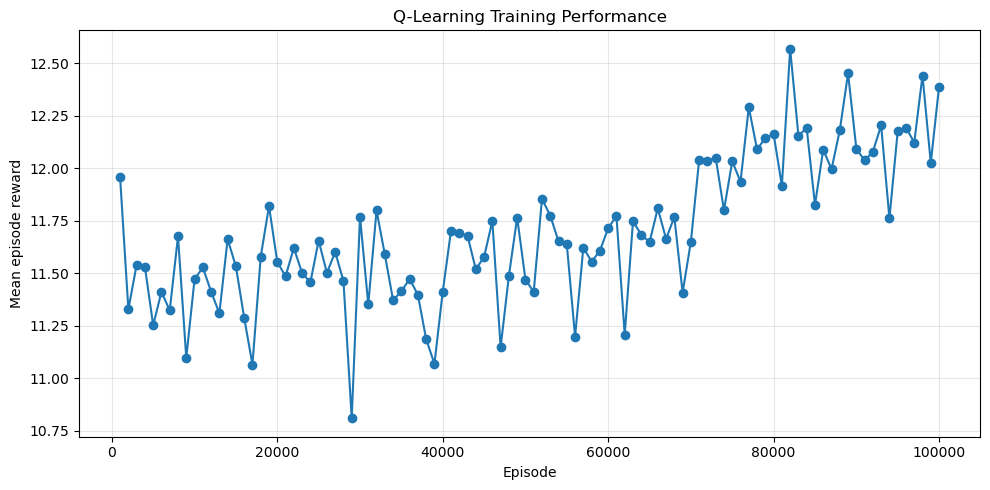


LEARNED Q-TABLE
                               Action_ID=0 | Insulin=1.00  \
State                                                       
State_ID=0 | Glucose=70.36                         0.9278   
State_ID=1 | Glucose=71.52                         0.3780   
State_ID=2 | Glucose=72.54                         1.1973   
State_ID=3 | Glucose=73.53                         0.5750   
State_ID=4 | Glucose=74.53                         1.4585   
...                                                   ...   
State_ID=115 | Glucose=185.50                     -0.0297   
State_ID=116 | Glucose=186.53                     -0.0572   
State_ID=117 | Glucose=187.60                     -0.0515   
State_ID=120 | Glucose=190.55                     -0.1838   
State_ID=121 | Glucose=191.49                     -0.1818   

                               Action_ID=3 | Insulin=2.36  \
State                                                       
State_ID=0 | Glucose=70.36                            NaN   
State_

In [47]:
# ==========================================
# CELL 8: MODEL-FREE Q-LEARNING
# ==========================================
# ------------------------------------------
# 1. AGENT SETTINGS
# ------------------------------------------

learning_rate = 0.01
gamma = 0.9
epsilon = 0.1

n_episodes = 100000
max_steps = 20

RANDOM_SEED = 42

rng = np.random.default_rng(RANDOM_SEED)


# ------------------------------------------
# 2. VALIDATE SETTINGS
# ------------------------------------------

if not (0 < learning_rate <= 1):
    raise ValueError("Learning rate must be in (0, 1].")

if not (0 <= gamma < 1):
    raise ValueError("Gamma must be in [0, 1).")

if not (0 <= epsilon <= 1):
    raise ValueError("Epsilon must be in [0, 1].")

if n_episodes <= 0 or max_steps <= 0:
    raise ValueError("Episodes and steps must be positive.")


# ------------------------------------------
# 3. CHECK STATE AND ACTION SPACES
# ------------------------------------------

# These variables were created in Cell 7B.

if set(state_ids) != set(env.state_ids):

    raise ValueError(
        "The states in Cell 7B do not match the "
        "states in the environment. Rerun Cell 7A and 7B."
    )

# Check that every action in the transition model
# is available in the environment.

environment_actions = set(
    action
    for actions in env._available_actions.values()
    for action in actions
)

if environment_actions != set(action_ids):

    raise ValueError(
        "The actions in Cell 7B do not match the "
        "actions in the environment."
    )


n_states = len(state_ids)
n_actions = len(action_ids)

print("Number of states:", n_states)
print("Number of actions:", n_actions)


# ------------------------------------------
# 4. INITIALISE Q-TABLE
# ------------------------------------------

# Rows represent states.
# Columns represent actions.

Q = np.zeros(
    (n_states, n_actions)
)

print("Q-table dimensions:", Q.shape)


# ------------------------------------------
# 5. INITIALISE TRAINING HISTORY
# ------------------------------------------

episode_rewards = []
episode_lengths = []

mean_rewards = []
mean_reward_episodes = []

report_interval = 1000


# ------------------------------------------
# 6. Q-LEARNING TRAINING
# ------------------------------------------

for episode in range(n_episodes):

    # Reset environment.

    state = int(env.reset())

    total_reward = 0.0
    steps_taken = 0

    for step in range(max_steps):

        # Get actions available in current state.

        available_actions = valid_actions[state]

        if len(available_actions) == 0:
            break


        # ----------------------------------
        # EPSILON-GREEDY ACTION SELECTION
        # ----------------------------------

        if rng.random() < epsilon:

            # Exploration.

            action = int(
                rng.choice(available_actions)
            )

        else:

            # Exploitation.

            s_idx = state_to_idx[state]

            action_values = [
                Q[s_idx, action_to_idx[a]]
                for a in available_actions
            ]

            best_index = int(
                np.argmax(action_values)
            )

            action = available_actions[best_index]


        # ----------------------------------
        # TAKE ACTION
        # ----------------------------------

        next_state, reward, done, info = env.step(action)

        next_state = int(next_state)
        reward = float(reward)

        total_reward += reward
        steps_taken += 1


        # ----------------------------------
        # Q-LEARNING UPDATE
        # ----------------------------------

        s_idx = state_to_idx[state]
        a_idx = action_to_idx[action]

        next_available_actions = valid_actions[next_state]

        if done or len(next_available_actions) == 0:

            target = reward

        else:

            next_s_idx = state_to_idx[next_state]

            next_q_values = [
                Q[
                    next_s_idx,
                    action_to_idx[a]
                ]
                for a in next_available_actions
            ]

            max_next_q = max(next_q_values)

            target = reward + gamma * max_next_q


        # Q-learning update equation.

        Q[s_idx, a_idx] += learning_rate * (
            target - Q[s_idx, a_idx]
        )


        # Move to next state.

        state = next_state

        if done:
            break


    # ----------------------------------
    # RECORD EPISODE RESULTS
    # ----------------------------------

    episode_rewards.append(total_reward)
    episode_lengths.append(steps_taken)


    # ----------------------------------
    # PRINT TRAINING PROGRESS
    # ----------------------------------

    if (episode + 1) % report_interval == 0:

        recent_mean_reward = np.mean(
            episode_rewards[-report_interval:]
        )

        mean_rewards.append(recent_mean_reward)
        mean_reward_episodes.append(episode + 1)

        print(
            f"Episode {episode + 1}/{n_episodes} | "
            f"Mean reward: {recent_mean_reward:.4f}"
        )


# ------------------------------------------
# 7. TRAINING SUMMARY
# ------------------------------------------

print("\nQ-LEARNING TRAINING COMPLETED")
print("--------------------------------")

print("Total episodes:", n_episodes)

print(
    "Mean reward over final 1000 episodes:",
    round(np.mean(episode_rewards[-1000:]), 4)
)

print(
    "Mean episode length over final 1000 episodes:",
    round(np.mean(episode_lengths[-1000:]), 2)
)


# ------------------------------------------
# 8. PLOT TRAINING PERFORMANCE
# ------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    mean_reward_episodes,
    mean_rewards,
    marker="o"
)

plt.xlabel("Episode")
plt.ylabel("Mean episode reward")

plt.title("Q-Learning Training Performance")

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------
# 9. CONSTRUCT LEARNED Q-TABLE
# ------------------------------------------

Q_display = np.full(
    (n_states, n_actions),
    np.nan
)

for state in state_ids:

    s_idx = state_to_idx[state]

    for action in valid_actions[state]:

        a_idx = action_to_idx[action]

        Q_display[s_idx, a_idx] = Q[s_idx, a_idx]


state_labels = [
    f"State_ID={s} | Glucose={glucose_lookup[s]:.2f}"
    for s in state_ids
]

action_labels = [
    f"Action_ID={a} | Insulin={insulin_lookup[a]:.2f}"
    for a in action_ids
]


learned_q_table = pd.DataFrame(
    Q_display,
    index=state_labels,
    columns=action_labels
)

learned_q_table.index.name = "State"

print("\nLEARNED Q-TABLE")

print(
    learned_q_table.round(4)
)

learned_q_table.to_csv(
    "diabetes_learned_Q_table.csv"
)

print("\nSaved: diabetes_learned_Q_table.csv")


# ------------------------------------------
# 10. EXTRACT LEARNED POLICY
# ------------------------------------------

learned_policy_rows = []

for state in state_ids:

    s_idx = state_to_idx[state]

    available_actions = valid_actions[state]

    if len(available_actions) == 0:
        continue

    best_action = max(
        available_actions,
        key=lambda a: Q[
            s_idx,
            action_to_idx[a]
        ]
    )

    learned_policy_rows.append({

        "State_ID": state,

        "Representative_Glucose": glucose_lookup[state],

        "Learned_Action_ID": best_action,

        "Representative_Insulin": insulin_lookup[best_action],

        "Learned_Q_Value": Q[
            s_idx,
            action_to_idx[best_action]
        ]

    })


learned_policy = pd.DataFrame(
    learned_policy_rows
)

print("\nLEARNED OPTIMAL POLICY")

print(learned_policy)

learned_policy.to_csv(
    "diabetes_learned_policy.csv",
    index=False
)

print("\nSaved: diabetes_learned_policy.csv")


# ------------------------------------------
# 11. SAVE TRAINING HISTORY
# ------------------------------------------

training_history = pd.DataFrame({

    "Episode": np.arange(1, n_episodes + 1),

    "Total_Reward": episode_rewards,

    "Episode_Length": episode_lengths

})

training_history.to_csv(
    "diabetes_q_learning_training_history.csv",
    index=False
)

print("\nSaved: diabetes_q_learning_training_history.csv")


In [48]:
# ============================================================
# CELL 9: SIMULATE U009 USING THE TRAINED Q-LEARNING AGENT
# ============================================================

# ------------------------------------------------------------
# 1. SELECT THE PATIENT
# ------------------------------------------------------------

PATIENT_ID = "U009"

patient_data = (
    filtered_test_transitions[
        filtered_test_transitions[PATIENT_COLUMN] == PATIENT_ID
    ]
    .sort_values(TIME_COLUMN)
    .copy()
)

print("PATIENT:", PATIENT_ID)
print("Original filtered decision epochs:", len(patient_data))


# ------------------------------------------------------------
# 2. CHECK THAT CELL 8 HAS BEEN RUN
# ------------------------------------------------------------

if "Q" not in globals():
    raise NameError(
        "Run Cell 8 first. Trained numerical Q-table Q is missing."
    )

if "env" not in globals():
    raise NameError("Environment 'env' is missing. Run Cell 7A.")

if "valid_actions" not in globals():
    raise NameError("valid_actions is missing. Run Cell 7B.")

if "state_to_idx" not in globals():
    raise NameError("state_to_idx is missing. Run Cell 7B.")

if "action_to_idx" not in globals():
    raise NameError("action_to_idx is missing. Run Cell 7B.")

if len(patient_data) == 0:
    raise ValueError(
        f"No filtered test transitions found for {PATIENT_ID}."
    )


# ------------------------------------------------------------
# 3. GET THE PATIENT'S INITIAL REAL OBSERVED STATE
# ------------------------------------------------------------

first_observation = (
    test_df[
        test_df[PATIENT_COLUMN] == PATIENT_ID
    ]
    .sort_values(TIME_COLUMN)
    .iloc[0]
)

initial_state = int(first_observation["State_ID"])

print("\nInitial observed state:", initial_state)


# ------------------------------------------------------------
# 4. VALIDATE THE INITIAL STATE
# ------------------------------------------------------------

if initial_state not in state_to_idx:
    raise ValueError(
        f"Initial state {initial_state} is not present "
        "in the training transition model. "
        "The RL agent cannot simulate from this state."
    )

if initial_state not in valid_actions:
    raise ValueError(
        f"No action-support information exists for "
        f"initial state {initial_state}."
    )


# ------------------------------------------------------------
# 5. PREPARE REPRESENTATIVE VALUES
# ------------------------------------------------------------

glucose_lookup = (
    representative_glucose_levels
    .set_index("State_ID")["Representative_Glucose"]
    .to_dict()
)

insulin_lookup = (
    representative_insulin_levels
    .set_index("Action_ID")["Representative_Insulin"]
    .to_dict()
)


# ------------------------------------------------------------
# 6. VALIDATE THE Q-TABLE DIMENSIONS
# ------------------------------------------------------------

if Q.shape != (len(state_ids), len(action_ids)):
    raise ValueError(
        "Q-table dimensions do not match the state/action spaces. "
        "Rerun Cell 7B and Cell 8 in order."
    )

print("\nTrained Q-table shape:", Q.shape)


# ------------------------------------------------------------
# 7. INITIALISE THE SIMULATION
# ------------------------------------------------------------

simulation_rng = np.random.default_rng(2026)

current_state = initial_state

simulation_records = []

n_simulation_steps = len(patient_data)

print("\nStarting RL simulation...")
print("Maximum simulation steps:", n_simulation_steps)


# ------------------------------------------------------------
# 8. RL AGENT ROLLOUT
# ------------------------------------------------------------

for epoch in range(n_simulation_steps):

    # ----------------------------------------
    # A. FIND ACTIONS SUPPORTED IN THIS STATE
    # ----------------------------------------

    available_actions = valid_actions.get(current_state, [])

    supported_actions = [
        a for a in available_actions
        if a in action_to_idx
    ]

    if len(supported_actions) == 0:
        print(
            f"\nSimulation stopped at epoch {epoch}: "
            f"No supported actions for state {current_state}."
        )
        break


    # ----------------------------------------
    # B. SELECT GREEDY ACTION USING TRAINED Q
    # ----------------------------------------

    current_state_idx = state_to_idx[current_state]

    action_values = [
        Q[
            current_state_idx,
            action_to_idx[action]
        ]
        for action in supported_actions
    ]

    best_position = int(np.argmax(action_values))

    selected_action = supported_actions[best_position]

    selected_q_value = float(action_values[best_position])


    # ----------------------------------------
    # C. GET EMPIRICAL TRANSITION PROBABILITIES
    # ----------------------------------------

    transition_key = (current_state, selected_action)

    if transition_key not in env._transition_probs:
        print(
            f"\nSimulation stopped at epoch {epoch}: "
            f"No empirical transition model for "
            f"state-action pair {transition_key}."
        )
        break

    next_states, probabilities = env._transition_probs[
        transition_key
    ]

    next_states = np.asarray(next_states, dtype=int)
    probabilities = np.asarray(probabilities, dtype=float)

    if len(next_states) == 0:
        print(
            f"\nSimulation stopped at epoch {epoch}: "
            "No possible next states."
        )
        break

    if not np.isclose(probabilities.sum(), 1.0):
        raise ValueError(
            f"Transition probabilities for {transition_key} "
            "do not sum to 1."
        )


    # ----------------------------------------
    # D. SAMPLE THE NEXT STATE
    # ----------------------------------------

    next_state = int(
        simulation_rng.choice(
            next_states,
            p=probabilities
        )
    )


    # ----------------------------------------
    # E. RECORD THE SIMULATED TRANSITION
    # ----------------------------------------

    simulation_records.append({

        "Decision_Epoch": epoch + 1,

        "State_ID": current_state,

        "Glucose_t": glucose_lookup.get(
            current_state, np.nan
        ),

        "Action_ID_Suggested": selected_action,

        "Insulin_Suggested": insulin_lookup.get(
            selected_action, np.nan
        ),

        "Q_Value": selected_q_value,

        "Next_State_ID": next_state,

        "Glucose_t_plus_1": glucose_lookup.get(
            next_state, np.nan
        )

    })


    # ----------------------------------------
    # F. MOVE TO THE NEXT STATE
    # ----------------------------------------

    current_state = next_state


# ------------------------------------------------------------
# 9. CREATE THE SIMULATED RL TRAJECTORY
# ------------------------------------------------------------

rl_trajectory = pd.DataFrame(simulation_records)

if rl_trajectory.empty:
    raise ValueError(
        "The RL simulation produced no transitions. "
        "Check the initial state and available actions."
    )


# ------------------------------------------------------------
# 10. ADD MATHEMATICAL STATE NOTATION
# ------------------------------------------------------------

rl_trajectory = rl_trajectory.rename(columns={

    "State_ID": "s_t",

    "Action_ID_Suggested": "a_t_suggested",

    "Next_State_ID": "s_t+1"

})


# ------------------------------------------------------------
# 11. DISPLAY SIMULATION RESULTS
# ------------------------------------------------------------

print("\nRL SIMULATION COMPLETED")
print("------------------------")

print("Patient:", PATIENT_ID)

print("Requested simulation steps:", n_simulation_steps)

print("Generated simulation steps:", len(rl_trajectory))

print("Initial state:", rl_trajectory["s_t"].iloc[0])

print("Final simulated state:", rl_trajectory["s_t+1"].iloc[-1])


display(
    rl_trajectory.head(20)
)


# ------------------------------------------------------------
# 12. SAVE THE SIMULATED RL TRAJECTORY
# ------------------------------------------------------------

output_file = "U009_trained_RL_agent_trajectory.csv"

rl_trajectory.to_csv(
    output_file,
    index=False
)

print("\nSaved:", output_file)



PATIENT: U009
Original filtered decision epochs: 1569

Initial observed state: 38

Trained Q-table shape: (118, 27)

Starting RL simulation...
Maximum simulation steps: 1569

RL SIMULATION COMPLETED
------------------------
Patient: U009
Requested simulation steps: 1569
Generated simulation steps: 1569
Initial state: 38
Final simulated state: 36


,Decision_Epoch,s_t,Glucose_t,a_t_suggested,Insulin_Suggested,Q_Value,s_t+1,Glucose_t_plus_1
0,1,38,108.527273,0,0.999256,9.944244,37,107.591772
1,2,37,107.591772,0,0.999256,9.923063,37,107.591772
2,3,37,107.591772,0,0.999256,9.923063,37,107.591772
3,4,37,107.591772,0,0.999256,9.923063,37,107.591772
4,5,37,107.591772,0,0.999256,9.923063,37,107.591772
5,6,37,107.591772,0,0.999256,9.923063,38,108.527273
6,7,38,108.527273,0,0.999256,9.944244,39,109.547552
7,8,39,109.547552,0,0.999256,9.962450,38,108.527273
8,9,38,108.527273,0,0.999256,9.944244,38,108.527273
9,10,38,108.527273,0,0.999256,9.944244,38,108.527273



Saved: U009_trained_RL_agent_trajectory.csv


In [49]:
# ============================================================
# CELL 9: SIMULATE U010 USING THE TRAINED Q-LEARNING AGENT
# ============================================================

# ------------------------------------------------------------
# 1. SELECT THE PATIENT
# ------------------------------------------------------------

PATIENT_ID = "U010"

patient_data = (
    filtered_test_transitions[
        filtered_test_transitions[PATIENT_COLUMN] == PATIENT_ID
    ]
    .sort_values(TIME_COLUMN)
    .copy()
)

print("PATIENT:", PATIENT_ID)
print("Original filtered decision epochs:", len(patient_data))


# ------------------------------------------------------------
# 2. CHECK THAT CELL 8 HAS BEEN RUN
# ------------------------------------------------------------

if "Q" not in globals():
    raise NameError(
        "Run Cell 8 first. Trained numerical Q-table Q is missing."
    )

if "env" not in globals():
    raise NameError("Environment 'env' is missing. Run Cell 7A.")

if "valid_actions" not in globals():
    raise NameError("valid_actions is missing. Run Cell 7B.")

if "state_to_idx" not in globals():
    raise NameError("state_to_idx is missing. Run Cell 7B.")

if "action_to_idx" not in globals():
    raise NameError("action_to_idx is missing. Run Cell 7B.")

if len(patient_data) == 0:
    raise ValueError(
        f"No filtered test transitions found for {PATIENT_ID}."
    )


# ------------------------------------------------------------
# 3. GET THE PATIENT'S INITIAL REAL OBSERVED STATE
# ------------------------------------------------------------

first_observation = (
    test_df[
        test_df[PATIENT_COLUMN] == PATIENT_ID
    ]
    .sort_values(TIME_COLUMN)
    .iloc[0]
)

initial_state = int(first_observation["State_ID"])

print("\nInitial observed state:", initial_state)


# ------------------------------------------------------------
# 4. VALIDATE THE INITIAL STATE
# ------------------------------------------------------------

if initial_state not in state_to_idx:
    raise ValueError(
        f"Initial state {initial_state} is not present "
        "in the training transition model. "
        "The RL agent cannot simulate from this state."
    )

if initial_state not in valid_actions:
    raise ValueError(
        f"No action-support information exists for "
        f"initial state {initial_state}."
    )


# ------------------------------------------------------------
# 5. PREPARE REPRESENTATIVE VALUES
# ------------------------------------------------------------

glucose_lookup = (
    representative_glucose_levels
    .set_index("State_ID")["Representative_Glucose"]
    .to_dict()
)

insulin_lookup = (
    representative_insulin_levels
    .set_index("Action_ID")["Representative_Insulin"]
    .to_dict()
)


# ------------------------------------------------------------
# 6. VALIDATE THE Q-TABLE DIMENSIONS
# ------------------------------------------------------------

if Q.shape != (len(state_ids), len(action_ids)):
    raise ValueError(
        "Q-table dimensions do not match the state/action spaces. "
        "Rerun Cell 7B and Cell 8 in order."
    )

print("\nTrained Q-table shape:", Q.shape)


# ------------------------------------------------------------
# 7. INITIALISE THE SIMULATION
# ------------------------------------------------------------

simulation_rng = np.random.default_rng(2026)

current_state = initial_state

simulation_records = []

n_simulation_steps = len(patient_data)

print("\nStarting RL simulation...")
print("Maximum simulation steps:", n_simulation_steps)


# ------------------------------------------------------------
# 8. RL AGENT ROLLOUT
# ------------------------------------------------------------

for epoch in range(n_simulation_steps):

    # ----------------------------------------
    # A. FIND ACTIONS SUPPORTED IN THIS STATE
    # ----------------------------------------

    available_actions = valid_actions.get(current_state, [])

    supported_actions = [
        a for a in available_actions
        if a in action_to_idx
    ]

    if len(supported_actions) == 0:
        print(
            f"\nSimulation stopped at epoch {epoch}: "
            f"No supported actions for state {current_state}."
        )
        break


    # ----------------------------------------
    # B. SELECT GREEDY ACTION USING TRAINED Q
    # ----------------------------------------

    current_state_idx = state_to_idx[current_state]

    action_values = [
        Q[
            current_state_idx,
            action_to_idx[action]
        ]
        for action in supported_actions
    ]

    best_position = int(np.argmax(action_values))

    selected_action = supported_actions[best_position]

    selected_q_value = float(action_values[best_position])


    # ----------------------------------------
    # C. GET EMPIRICAL TRANSITION PROBABILITIES
    # ----------------------------------------

    transition_key = (current_state, selected_action)

    if transition_key not in env._transition_probs:
        print(
            f"\nSimulation stopped at epoch {epoch}: "
            f"No empirical transition model for "
            f"state-action pair {transition_key}."
        )
        break

    next_states, probabilities = env._transition_probs[
        transition_key
    ]

    next_states = np.asarray(next_states, dtype=int)
    probabilities = np.asarray(probabilities, dtype=float)

    if len(next_states) == 0:
        print(
            f"\nSimulation stopped at epoch {epoch}: "
            "No possible next states."
        )
        break

    if not np.isclose(probabilities.sum(), 1.0):
        raise ValueError(
            f"Transition probabilities for {transition_key} "
            "do not sum to 1."
        )


    # ----------------------------------------
    # D. SAMPLE THE NEXT STATE
    # ----------------------------------------

    next_state = int(
        simulation_rng.choice(
            next_states,
            p=probabilities
        )
    )


    # ----------------------------------------
    # E. RECORD THE SIMULATED TRANSITION
    # ----------------------------------------

    simulation_records.append({

        "Decision_Epoch": epoch + 1,

        "State_ID": current_state,

        "Glucose_t": glucose_lookup.get(
            current_state, np.nan
        ),

        "Action_ID_Suggested": selected_action,

        "Insulin_Suggested": insulin_lookup.get(
            selected_action, np.nan
        ),

        "Q_Value": selected_q_value,

        "Next_State_ID": next_state,

        "Glucose_t_plus_1": glucose_lookup.get(
            next_state, np.nan
        )

    })


    # ----------------------------------------
    # F. MOVE TO THE NEXT STATE
    # ----------------------------------------

    current_state = next_state


# ------------------------------------------------------------
# 9. CREATE THE SIMULATED RL TRAJECTORY
# ------------------------------------------------------------

rl_trajectory = pd.DataFrame(simulation_records)

if rl_trajectory.empty:
    raise ValueError(
        "The RL simulation produced no transitions. "
        "Check the initial state and available actions."
    )


# ------------------------------------------------------------
# 10. ADD MATHEMATICAL STATE NOTATION
# ------------------------------------------------------------

rl_trajectory = rl_trajectory.rename(columns={

    "State_ID": "s_t",

    "Action_ID_Suggested": "a_t_suggested",

    "Next_State_ID": "s_t+1"

})


# ------------------------------------------------------------
# 11. DISPLAY SIMULATION RESULTS
# ------------------------------------------------------------

print("\nRL SIMULATION COMPLETED")
print("------------------------")

print("Patient:", PATIENT_ID)

print("Requested simulation steps:", n_simulation_steps)

print("Generated simulation steps:", len(rl_trajectory))

print("Initial state:", rl_trajectory["s_t"].iloc[0])

print("Final simulated state:", rl_trajectory["s_t+1"].iloc[-1])


display(
    rl_trajectory.head(20)
)


# ------------------------------------------------------------
# 12. SAVE THE SIMULATED RL TRAJECTORY
# ------------------------------------------------------------

output_file = "U010_trained_RL_agent_trajectory.csv"

rl_trajectory.to_csv(
    output_file,
    index=False
)

print("\nSaved:", output_file)

PATIENT: U010
Original filtered decision epochs: 1539

Initial observed state: 42

Trained Q-table shape: (118, 27)

Starting RL simulation...
Maximum simulation steps: 1539

RL SIMULATION COMPLETED
------------------------
Patient: U010
Requested simulation steps: 1539
Generated simulation steps: 1539
Initial state: 42
Final simulated state: 41


,Decision_Epoch,s_t,Glucose_t,a_t_suggested,Insulin_Suggested,Q_Value,s_t+1,Glucose_t_plus_1
0,1,42,112.546893,0,0.999256,9.968442,41,111.551592
1,2,41,111.551592,0,0.999256,9.971144,41,111.551592
2,3,41,111.551592,0,0.999256,9.971144,41,111.551592
3,4,41,111.551592,0,0.999256,9.971144,41,111.551592
4,5,41,111.551592,0,0.999256,9.971144,41,111.551592
5,6,41,111.551592,0,0.999256,9.971144,42,112.546893
6,7,42,112.546893,0,0.999256,9.968442,43,113.513450
7,8,43,113.513450,10,5.022941,9.968012,42,112.546893
8,9,42,112.546893,0,0.999256,9.968442,42,112.546893
9,10,42,112.546893,0,0.999256,9.968442,42,112.546893



Saved: U010_trained_RL_agent_trajectory.csv


In [50]:
# ============================================================
# CELL 10: INTERACTIVE PLOTS — ACTUAL VS RL-SIMULATED
# PATIENT U009
# ============================================================

# ------------------------------------------------------------
# 1. SELECT PATIENT AND PREPARE ACTUAL DATA
# ------------------------------------------------------------

PATIENT_ID = "U009"

# Actual observed trajectory under recorded clinician treatment.
actual_data = (
    filtered_test_transitions[
        filtered_test_transitions[PATIENT_COLUMN] == PATIENT_ID
    ]
    .sort_values(TIME_COLUMN)
    .copy()
    .reset_index(drop=True)
)

# Number actual decision epochs from 1.
actual_data["Decision_Epoch"] = np.arange(
    1, len(actual_data) + 1
)

# Actual glucose at the current and next observations.
actual_data["Actual_Glucose"] = (
    actual_data["Representative_Glucose"]
)

actual_data["Actual_Next_Glucose"] = (
    actual_data["Next_Representative_Glucose"]
)


# ------------------------------------------------------------
# 2. LOAD THE RL-SIMULATED TRAJECTORY
# ------------------------------------------------------------

rl_data = pd.read_csv(
    f"{PATIENT_ID}_trained_RL_agent_trajectory.csv"
).reset_index(drop=True)

if rl_data.empty:
    raise ValueError("The RL trajectory is empty.")

rl_data["Decision_Epoch"] = np.arange(
    1, len(rl_data) + 1
)


# ------------------------------------------------------------
# 3. CHECK DATA AVAILABILITY
# ------------------------------------------------------------

if actual_data.empty:
    raise ValueError(
        f"No actual filtered observations found for {PATIENT_ID}."
    )

required_rl_columns = [
    "Glucose_t",
    "Glucose_t_plus_1",
    "Insulin_Suggested",
    "Q_Value"
]

missing_columns = [
    col for col in required_rl_columns
    if col not in rl_data.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns in RL trajectory: {missing_columns}"
    )

print("PATIENT:", PATIENT_ID)
print("Actual decision epochs:", len(actual_data))
print("RL-simulated decision epochs:", len(rl_data))


# ------------------------------------------------------------
# 4. PLOT ACTUAL VS RL-SIMULATED GLUCOSE TRAJECTORY
# ------------------------------------------------------------

fig1 = go.Figure()

# Actual clinician-treated trajectory.
fig1.add_trace(
    go.Scatter(
        x=actual_data["Decision_Epoch"],
        y=actual_data["Actual_Glucose"],
        mode="lines",
        name="Actual glucose — clinician-treated",
        line=dict(width=2),
        hovertemplate=(
            "Decision epoch: %{x}<br>"
            "Actual glucose: %{y:.3f}"
            "<extra></extra>"
        )
    )
)

# RL-simulated trajectory.
fig1.add_trace(
    go.Scatter(
        x=rl_data["Decision_Epoch"],
        y=rl_data["Glucose_t"],
        mode="lines",
        name="RL-simulated glucose",
        line=dict(width=2, dash="dash"),
        hovertemplate=(
            "Decision epoch: %{x}<br>"
            "RL glucose: %{y:.3f}"
            "<extra></extra>"
        )
    )
)

fig1.update_layout(
    title=(
        "U009: Actual vs RL-Simulated Glucose Trajectory"
    ),
    xaxis_title="Decision epoch",
    yaxis_title="Representative glucose",
    hovermode="x unified",
    template="plotly_white",
    height=650,
    legend=dict(orientation="h", y=1.12)
)

fig1.update_xaxes(
    rangeslider_visible=True,
    rangeselector=dict(
        buttons=[
            dict(count=100, label="100 epochs", step="all"),
            dict(count=250, label="250 epochs", step="all"),
            dict(count=500, label="500 epochs", step="all"),
            dict(step="all", label="All")
        ]
    )
)

fig1.show(
    config={"scrollZoom": True, "displaylogo": False}
)


# ------------------------------------------------------------
# 5. PLOT NEXT-STATE GLUCOSE TRAJECTORIES
# ------------------------------------------------------------

fig2 = go.Figure()

fig2.add_trace(
    go.Scatter(
        x=actual_data["Decision_Epoch"],
        y=actual_data["Actual_Next_Glucose"],
        mode="lines",
        name="Actual next glucose",
        line=dict(width=2),
        hovertemplate=(
            "Decision epoch: %{x}<br>"
            "Actual next glucose: %{y:.3f}"
            "<extra></extra>"
        )
    )
)

fig2.add_trace(
    go.Scatter(
        x=rl_data["Decision_Epoch"],
        y=rl_data["Glucose_t_plus_1"],
        mode="lines",
        name="RL-simulated next glucose",
        line=dict(width=2, dash="dash"),
        hovertemplate=(
            "Decision epoch: %{x}<br>"
            "RL next glucose: %{y:.3f}"
            "<extra></extra>"
        )
    )
)

fig2.update_layout(
    title=(
        "U009: Actual vs RL-Simulated Next-State Glucose"
    ),
    xaxis_title="Decision epoch",
    yaxis_title="Representative next-state glucose",
    hovermode="x unified",
    template="plotly_white",
    height=600
)

fig2.update_xaxes(rangeslider_visible=True)

fig2.show(
    config={"scrollZoom": True, "displaylogo": False}
)


# ------------------------------------------------------------
# 6. PLOT THE RL AGENT'S SUGGESTED INSULIN ACTIONS
# ------------------------------------------------------------

fig3 = go.Figure()

fig3.add_trace(
    go.Scatter(
        x=rl_data["Decision_Epoch"],
        y=rl_data["Insulin_Suggested"],
        mode="lines+markers",
        name="RL-suggested insulin",
        marker=dict(size=4),
        line=dict(width=1.5),
        hovertemplate=(
            "Decision epoch: %{x}<br>"
            "Suggested insulin: %{y:.3f}"
            "<extra></extra>"
        )
    )
)

fig3.update_layout(
    title="U009: Insulin Actions Suggested by the Trained RL Agent",
    xaxis_title="Decision epoch",
    yaxis_title="Representative insulin action",
    hovermode="x unified",
    template="plotly_white",
    height=500
)

fig3.update_xaxes(rangeslider_visible=True)

fig3.show(
    config={"scrollZoom": True, "displaylogo": False}
)


# ------------------------------------------------------------
# 7. PLOT THE Q-VALUES OF THE SELECTED ACTIONS
# ------------------------------------------------------------

fig4 = go.Figure()

fig4.add_trace(
    go.Scatter(
        x=rl_data["Decision_Epoch"],
        y=rl_data["Q_Value"],
        mode="lines+markers",
        name="Selected action Q-value",
        marker=dict(size=4),
        line=dict(width=1.5),
        hovertemplate=(
            "Decision epoch: %{x}<br>"
            "Q-value: %{y:.4f}"
            "<extra></extra>"
        )
    )
)

fig4.update_layout(
    title="U009: Q-Values of RL-Suggested Actions",
    xaxis_title="Decision epoch",
    yaxis_title="Learned Q-value",
    hovermode="x unified",
    template="plotly_white",
    height=500
)

fig4.update_xaxes(rangeslider_visible=True)

fig4.show(
    config={"scrollZoom": True, "displaylogo": False}
)


# ------------------------------------------------------------
# 8. DISPLAY THE ACTUAL CLINICIAN-TREATED DATA
# ------------------------------------------------------------

print("\nACTUAL CLINICIAN-TREATED TRAJECTORY")

display(
    actual_data[
        [
            "Decision_Epoch",
            "State_ID",
            "Action_ID",
            "Next_State_ID",
            "Actual_Glucose",
            "Actual_Next_Glucose",
            "Elapsed_Minutes"
        ]
    ].head(20)
)


# ------------------------------------------------------------
# 9. DISPLAY THE RL-SIMULATED DATA
# ------------------------------------------------------------

print("\nRL-SIMULATED TRAJECTORY")

display(
    rl_data[
        [
            "Decision_Epoch",
            "s_t",
            "a_t_suggested",
            "s_t+1",
            "Glucose_t",
            "Insulin_Suggested",
            "Glucose_t_plus_1",
            "Q_Value"
        ]
    ].head(20)
)


# ------------------------------------------------------------
# 10. SAVE THE COMPARISON DATA
# ------------------------------------------------------------

actual_data.to_csv(
    "U009_actual_clinician_trajectory.csv",
    index=False
)

rl_data.to_csv(
    "U009_trained_RL_agent_trajectory.csv",
    index=False
)

print("\nINTERACTIVE PLOTTING COMPLETED.")
print("Patient:", PATIENT_ID)



PATIENT: U009
Actual decision epochs: 1569
RL-simulated decision epochs: 1569



ACTUAL CLINICIAN-TREATED TRAJECTORY


,Decision_Epoch,State_ID,Action_ID,Next_State_ID,Actual_Glucose,Actual_Next_Glucose,Elapsed_Minutes
0,1,38,0,38,108.527273,108.527273,5.0
1,2,38,0,38,108.527273,108.527273,15.0
2,3,38,0,38,108.527273,108.527273,10.0
3,4,38,0,37,108.527273,107.591772,15.0
4,5,37,0,35,107.591772,105.564045,20.0
5,6,35,0,36,105.564045,106.550370,10.0
6,7,36,0,36,106.550370,106.550370,15.0
7,8,36,0,35,106.550370,105.564045,5.0
8,9,35,0,34,105.564045,104.524074,5.0
9,10,34,4,32,104.524074,102.537681,5.0



RL-SIMULATED TRAJECTORY


,Decision_Epoch,s_t,a_t_suggested,s_t+1,Glucose_t,Insulin_Suggested,Glucose_t_plus_1,Q_Value
0,1,38,0,37,108.527273,0.999256,107.591772,9.944244
1,2,37,0,37,107.591772,0.999256,107.591772,9.923063
2,3,37,0,37,107.591772,0.999256,107.591772,9.923063
3,4,37,0,37,107.591772,0.999256,107.591772,9.923063
4,5,37,0,37,107.591772,0.999256,107.591772,9.923063
5,6,37,0,38,107.591772,0.999256,108.527273,9.923063
6,7,38,0,39,108.527273,0.999256,109.547552,9.944244
7,8,39,0,38,109.547552,0.999256,108.527273,9.962450
8,9,38,0,38,108.527273,0.999256,108.527273,9.944244
9,10,38,0,38,108.527273,0.999256,108.527273,9.944244



INTERACTIVE PLOTTING COMPLETED.
Patient: U009


In [51]:

# ============================================================
# CELL 10: INTERACTIVE PLOTS — ACTUAL VS RL-SIMULATED
# PATIENT U010
# ============================================================

# ------------------------------------------------------------
# 1. SELECT PATIENT AND PREPARE ACTUAL DATA
# ------------------------------------------------------------

PATIENT_ID = "U010"

# Actual observed trajectory under recorded clinician treatment.
actual_data = (
    filtered_test_transitions[
        filtered_test_transitions[PATIENT_COLUMN] == PATIENT_ID
    ]
    .sort_values(TIME_COLUMN)
    .copy()
    .reset_index(drop=True)
)

# Number actual decision epochs from 1.
actual_data["Decision_Epoch"] = np.arange(
    1, len(actual_data) + 1
)

# Actual glucose at the current and next observations.
actual_data["Actual_Glucose"] = (
    actual_data["Representative_Glucose"]
)

actual_data["Actual_Next_Glucose"] = (
    actual_data["Next_Representative_Glucose"]
)


# ------------------------------------------------------------
# 2. LOAD THE RL-SIMULATED TRAJECTORY
# ------------------------------------------------------------

rl_data = pd.read_csv(
    f"{PATIENT_ID}_trained_RL_agent_trajectory.csv"
).reset_index(drop=True)

if rl_data.empty:
    raise ValueError("The RL trajectory is empty.")

rl_data["Decision_Epoch"] = np.arange(
    1, len(rl_data) + 1
)


# ------------------------------------------------------------
# 3. CHECK DATA AVAILABILITY
# ------------------------------------------------------------

if actual_data.empty:
    raise ValueError(
        f"No actual filtered observations found for {PATIENT_ID}."
    )

required_rl_columns = [
    "Glucose_t",
    "Glucose_t_plus_1",
    "Insulin_Suggested",
    "Q_Value"
]

missing_columns = [
    col for col in required_rl_columns
    if col not in rl_data.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns in RL trajectory: {missing_columns}"
    )

print("PATIENT:", PATIENT_ID)
print("Actual decision epochs:", len(actual_data))
print("RL-simulated decision epochs:", len(rl_data))


# ------------------------------------------------------------
# 4. PLOT ACTUAL VS RL-SIMULATED GLUCOSE TRAJECTORY
# ------------------------------------------------------------

fig1 = go.Figure()

# Actual clinician-treated trajectory.
fig1.add_trace(
    go.Scatter(
        x=actual_data["Decision_Epoch"],
        y=actual_data["Actual_Glucose"],
        mode="lines",
        name="Actual glucose — clinician-treated",
        line=dict(width=2),
        hovertemplate=(
            "Decision epoch: %{x}<br>"
            "Actual glucose: %{y:.3f}"
            "<extra></extra>"
        )
    )
)

# RL-simulated trajectory.
fig1.add_trace(
    go.Scatter(
        x=rl_data["Decision_Epoch"],
        y=rl_data["Glucose_t"],
        mode="lines",
        name="RL-simulated glucose",
        line=dict(width=2, dash="dash"),
        hovertemplate=(
            "Decision epoch: %{x}<br>"
            "RL glucose: %{y:.3f}"
            "<extra></extra>"
        )
    )
)

fig1.update_layout(
    title=(
        "U010: Actual vs RL-Simulated Glucose Trajectory"
    ),
    xaxis_title="Decision epoch",
    yaxis_title="Representative glucose",
    hovermode="x unified",
    template="plotly_white",
    height=650,
    legend=dict(orientation="h", y=1.12)
)

fig1.update_xaxes(
    rangeslider_visible=True,
    rangeselector=dict(
        buttons=[
            dict(count=100, label="100 epochs", step="all"),
            dict(count=250, label="250 epochs", step="all"),
            dict(count=500, label="500 epochs", step="all"),
            dict(step="all", label="All")
        ]
    )
)

fig1.show(
    config={"scrollZoom": True, "displaylogo": False}
)


# ------------------------------------------------------------
# 5. PLOT NEXT-STATE GLUCOSE TRAJECTORIES
# ------------------------------------------------------------

fig2 = go.Figure()

fig2.add_trace(
    go.Scatter(
        x=actual_data["Decision_Epoch"],
        y=actual_data["Actual_Next_Glucose"],
        mode="lines",
        name="Actual next glucose",
        line=dict(width=2),
        hovertemplate=(
            "Decision epoch: %{x}<br>"
            "Actual next glucose: %{y:.3f}"
            "<extra></extra>"
        )
    )
)

fig2.add_trace(
    go.Scatter(
        x=rl_data["Decision_Epoch"],
        y=rl_data["Glucose_t_plus_1"],
        mode="lines",
        name="RL-simulated next glucose",
        line=dict(width=2, dash="dash"),
        hovertemplate=(
            "Decision epoch: %{x}<br>"
            "RL next glucose: %{y:.3f}"
            "<extra></extra>"
        )
    )
)

fig2.update_layout(
    title=(
        "U010: Actual vs RL-Simulated Next-State Glucose"
    ),
    xaxis_title="Decision epoch",
    yaxis_title="Representative next-state glucose",
    hovermode="x unified",
    template="plotly_white",
    height=600
)

fig2.update_xaxes(rangeslider_visible=True)

fig2.show(
    config={"scrollZoom": True, "displaylogo": False}
)


# ------------------------------------------------------------
# 6. PLOT THE RL AGENT'S SUGGESTED INSULIN ACTIONS
# ------------------------------------------------------------

fig3 = go.Figure()

fig3.add_trace(
    go.Scatter(
        x=rl_data["Decision_Epoch"],
        y=rl_data["Insulin_Suggested"],
        mode="lines+markers",
        name="RL-suggested insulin",
        marker=dict(size=4),
        line=dict(width=1.5),
        hovertemplate=(
            "Decision epoch: %{x}<br>"
            "Suggested insulin: %{y:.3f}"
            "<extra></extra>"
        )
    )
)

fig3.update_layout(
    title="U010: Insulin Actions Suggested by the Trained RL Agent",
    xaxis_title="Decision epoch",
    yaxis_title="Representative insulin action",
    hovermode="x unified",
    template="plotly_white",
    height=500
)

fig3.update_xaxes(rangeslider_visible=True)

fig3.show(
    config={"scrollZoom": True, "displaylogo": False}
)


# ------------------------------------------------------------
# 7. PLOT THE Q-VALUES OF THE SELECTED ACTIONS
# ------------------------------------------------------------

fig4 = go.Figure()

fig4.add_trace(
    go.Scatter(
        x=rl_data["Decision_Epoch"],
        y=rl_data["Q_Value"],
        mode="lines+markers",
        name="Selected action Q-value",
        marker=dict(size=4),
        line=dict(width=1.5),
        hovertemplate=(
            "Decision epoch: %{x}<br>"
            "Q-value: %{y:.4f}"
            "<extra></extra>"
        )
    )
)

fig4.update_layout(
    title="U010: Q-Values of RL-Suggested Actions",
    xaxis_title="Decision epoch",
    yaxis_title="Learned Q-value",
    hovermode="x unified",
    template="plotly_white",
    height=500
)

fig4.update_xaxes(rangeslider_visible=True)

fig4.show(
    config={"scrollZoom": True, "displaylogo": False}
)


# ------------------------------------------------------------
# 8. DISPLAY THE ACTUAL CLINICIAN-TREATED DATA
# ------------------------------------------------------------

print("\nACTUAL CLINICIAN-TREATED TRAJECTORY")

display(
    actual_data[
        [
            "Decision_Epoch",
            "State_ID",
            "Action_ID",
            "Next_State_ID",
            "Actual_Glucose",
            "Actual_Next_Glucose",
            "Elapsed_Minutes"
        ]
    ].head(20)
)


# ------------------------------------------------------------
# 9. DISPLAY THE RL-SIMULATED DATA
# ------------------------------------------------------------

print("\nRL-SIMULATED TRAJECTORY")

display(
    rl_data[
        [
            "Decision_Epoch",
            "s_t",
            "a_t_suggested",
            "s_t+1",
            "Glucose_t",
            "Insulin_Suggested",
            "Glucose_t_plus_1",
            "Q_Value"
        ]
    ].head(20)
)


# ------------------------------------------------------------
# 10. SAVE THE COMPARISON DATA
# ------------------------------------------------------------

actual_data.to_csv(
    "U010_actual_clinician_trajectory.csv",
    index=False
)

rl_data.to_csv(
    "U010_trained_RL_agent_trajectory.csv",
    index=False
)

print("\nINTERACTIVE PLOTTING COMPLETED.")
print("Patient:", PATIENT_ID)



PATIENT: U010
Actual decision epochs: 1539
RL-simulated decision epochs: 1539



ACTUAL CLINICIAN-TREATED TRAJECTORY


,Decision_Epoch,State_ID,Action_ID,Next_State_ID,Actual_Glucose,Actual_Next_Glucose,Elapsed_Minutes
0,1,42,0,43,112.546893,113.513450,5.0
1,2,43,0,43,113.513450,113.513450,5.0
2,3,43,0,43,113.513450,113.513450,10.0
3,4,43,0,44,113.513450,114.522794,15.0
4,5,44,0,41,114.522794,111.551592,20.0
5,6,41,19,40,111.551592,110.503165,5.0
6,7,40,0,36,110.503165,106.550370,10.0
7,8,36,0,30,106.550370,100.592857,10.0
8,9,30,0,25,100.592857,95.511486,5.0
9,10,25,0,19,95.511486,89.547368,5.0



RL-SIMULATED TRAJECTORY


,Decision_Epoch,s_t,a_t_suggested,s_t+1,Glucose_t,Insulin_Suggested,Glucose_t_plus_1,Q_Value
0,1,42,0,41,112.546893,0.999256,111.551592,9.968442
1,2,41,0,41,111.551592,0.999256,111.551592,9.971144
2,3,41,0,41,111.551592,0.999256,111.551592,9.971144
3,4,41,0,41,111.551592,0.999256,111.551592,9.971144
4,5,41,0,41,111.551592,0.999256,111.551592,9.971144
5,6,41,0,42,111.551592,0.999256,112.546893,9.971144
6,7,42,0,43,112.546893,0.999256,113.513450,9.968442
7,8,43,10,42,113.513450,5.022941,112.546893,9.968012
8,9,42,0,42,112.546893,0.999256,112.546893,9.968442
9,10,42,0,42,112.546893,0.999256,112.546893,9.968442



INTERACTIVE PLOTTING COMPLETED.
Patient: U010


In [52]:
# ============================================================
# RL TRAJECTORY DIAGNOSTIC EVALUATION
# ============================================================

def audit_rl_trajectory(df, target_glucose=120.0):
    print("============================================================")
    print("               RL POLICY TRAJECTORY AUDIT                   ")
    print("============================================================")

    # 1. Episode Length & Completion
    total_steps = len(df)
    print(f"1. Trajectory Length          : {total_steps} epochs")

    # 2. Glucose Range & Stability
    mean_g = df["Glucose_t"].mean()
    min_g = df["Glucose_t"].min()
    max_g = df["Glucose_t"].max()
    std_g = df["Glucose_t"].std()

    in_range_pct = ((df["Glucose_t"] >= 70) & (df["Glucose_t"] <= 180)).mean() * 100

    print(f"2. Mean Glucose               : {mean_g:.2f} mg/dL (Target: {target_glucose})")
    print(f"   Glucose Range (Min / Max)  : {min_g:.1f} / {max_g:.1f} mg/dL")
    print(f"   Time in Target Range (TIR) : {in_range_pct:.1f}%")
    print(f"   Glucose Std Dev            : {std_g:.2f} mg/dL")

    # 3. Action Distribution
    unique_actions = df["a_t_suggested"].nunique()
    print(f"3. Unique Actions Suggested    : {unique_actions}")

    # 4. Q-Value Range
    print(f"4. Mean Selected Q-Value       : {df['Q_Value'].mean():.4f}")
    print(f"   Q-Value Std Dev            : {df['Q_Value'].std():.4f}")
    print("============================================================")

# Run audit on generated RL trajectory
audit_rl_trajectory(rl_trajectory)

               RL POLICY TRAJECTORY AUDIT                   
1. Trajectory Length          : 1539 epochs
2. Mean Glucose               : 110.36 mg/dL (Target: 120.0)
   Glucose Range (Min / Max)  : 104.5 / 114.5 mg/dL
   Time in Target Range (TIR) : 100.0%
   Glucose Std Dev            : 2.10 mg/dL
3. Unique Actions Suggested    : 4
4. Mean Selected Q-Value       : 9.9540
   Q-Value Std Dev            : 0.0270


In [53]:
# ============================================================
# CLINICIAN VS. RL AGENT DOSING COMPARISON (PATIENT U009)
# ============================================================
rl_data = pd.read_csv("U009_trained_RL_agent_trajectory.csv")
actual_data = pd.read_csv("U009_actual_clinician_trajectory.csv")
# 1. Align trajectories by decision epoch
comparison_df = pd.DataFrame({
    "Decision_Epoch": actual_data["Decision_Epoch"],
    "Glucose_Observed": actual_data["Actual_Glucose"],
    "Clinician_Action_ID": actual_data["Action_ID"],
    "Clinician_Insulin": actual_data["Representative_Insulin"],
    "RL_Action_ID": rl_data["a_t_suggested"],
    "RL_Insulin": rl_data["Insulin_Suggested"],
})

# Calculate metrics
comparison_df["Action_Match"] = comparison_df["Clinician_Action_ID"] == comparison_df["RL_Action_ID"]
comparison_df["Dose_Difference"] = comparison_df["RL_Insulin"] - comparison_df["Clinician_Insulin"]
comparison_df["Abs_Dose_Difference"] = comparison_df["Dose_Difference"].abs()

# Summary statistics
exact_match_pct = comparison_df["Action_Match"].mean() * 100
mean_diff = comparison_df["Dose_Difference"].mean()
mean_abs_diff = comparison_df["Abs_Dose_Difference"].mean()

print("============================================================")
print("       CLINICIAN VS. RL POLICY DOSING COMPARISON (U009)     ")
print("============================================================")
print(f"Total Decision Epochs Evaluated : {len(comparison_df)}")
print(f"Exact Action Agreement          : {exact_match_pct:.2f}%")
print(f"Mean Dose Difference (RL - Clin): {mean_diff:+.3f} Units")
print(f"Mean Absolute Dose Difference   : {mean_abs_diff:.3f} Units")
print("============================================================")

# 2. Display sample side-by-side comparison
print("\nSample Step-by-Step Decisions:")
display(comparison_df[["Decision_Epoch", "Glucose_Observed", "Clinician_Insulin", "RL_Insulin", "Dose_Difference", "Action_Match"]].head(15))
comparison_df.to_csv("Patient_9_comparison_df.csv")

       CLINICIAN VS. RL POLICY DOSING COMPARISON (U009)     
Total Decision Epochs Evaluated : 1569
Exact Action Agreement          : 88.78%
Mean Dose Difference (RL - Clin): +0.191 Units
Mean Absolute Dose Difference   : 0.492 Units

Sample Step-by-Step Decisions:


,Decision_Epoch,Glucose_Observed,Clinician_Insulin,RL_Insulin,Dose_Difference,Action_Match
0,1,108.527273,0.999256,0.999256,0.000000,True
1,2,108.527273,0.999256,0.999256,0.000000,True
2,3,108.527273,0.999256,0.999256,0.000000,True
3,4,108.527273,0.999256,0.999256,0.000000,True
4,5,107.591772,0.999256,0.999256,0.000000,True
5,6,105.564045,0.999256,0.999256,0.000000,True
6,7,106.550370,0.999256,0.999256,0.000000,True
7,8,106.550370,0.999256,0.999256,0.000000,True
8,9,105.564045,0.999256,0.999256,0.000000,True
9,10,104.524074,2.660000,0.999256,-1.660744,False


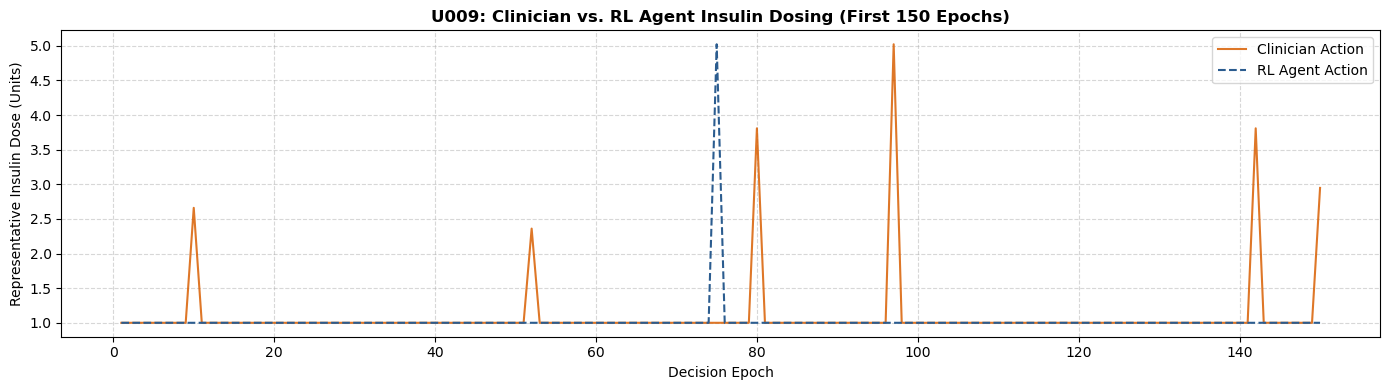

In [54]:
# Plot actual clinician insulin vs. RL suggested insulin
plt.figure(figsize=(14, 4))
plt.plot(comparison_df["Decision_Epoch"][:150], comparison_df["Clinician_Insulin"][:150], label="Clinician Action", color="#d95f02", alpha=0.85, linewidth=1.5)
plt.plot(comparison_df["Decision_Epoch"][:150], comparison_df["RL_Insulin"][:150], label="RL Agent Action", color="#2b5c8f", linestyle="--", linewidth=1.5)
plt.title("U009: Clinician vs. RL Agent Insulin Dosing (First 150 Epochs)", fontsize=12, fontweight="bold")
plt.xlabel("Decision Epoch")
plt.ylabel("Representative Insulin Dose (Units)")
plt.legend(loc="upper right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [55]:
# ============================================================
# CLINICIAN VS. RL AGENT DOSING COMPARISON (PATIENT U010)
# ============================================================
rl_data = pd.read_csv("U010_trained_RL_agent_trajectory.csv")
actual_data = pd.read_csv("U010_actual_clinician_trajectory.csv")
# 1. Align trajectories by decision epoch
comparison_df = pd.DataFrame({
    "Decision_Epoch": actual_data["Decision_Epoch"],
    "Glucose_Observed": actual_data["Actual_Glucose"],
    "Clinician_Action_ID": actual_data["Action_ID"],
    "Clinician_Insulin": actual_data["Representative_Insulin"],
    "RL_Action_ID": rl_data["a_t_suggested"],
    "RL_Insulin": rl_data["Insulin_Suggested"],
})

# Calculate metrics
comparison_df["Action_Match"] = comparison_df["Clinician_Action_ID"] == comparison_df["RL_Action_ID"]
comparison_df["Dose_Difference"] = comparison_df["RL_Insulin"] - comparison_df["Clinician_Insulin"]
comparison_df["Abs_Dose_Difference"] = comparison_df["Dose_Difference"].abs()

# Summary statistics
exact_match_pct = comparison_df["Action_Match"].mean() * 100
mean_diff = comparison_df["Dose_Difference"].mean()
mean_abs_diff = comparison_df["Abs_Dose_Difference"].mean()

print("============================================================")
print("       CLINICIAN VS. RL POLICY DOSING COMPARISON (U009)     ")
print("============================================================")
print(f"Total Decision Epochs Evaluated : {len(comparison_df)}")
print(f"Exact Action Agreement          : {exact_match_pct:.2f}%")
print(f"Mean Dose Difference (RL - Clin): {mean_diff:+.3f} Units")
print(f"Mean Absolute Dose Difference   : {mean_abs_diff:.3f} Units")
print("============================================================")

# 2. Display sample side-by-side comparison
print("\nSample Step-by-Step Decisions:")
display(comparison_df[["Decision_Epoch", "Glucose_Observed", "Clinician_Insulin", "RL_Insulin", "Dose_Difference", "Action_Match"]].head(15))
comparison_df.to_csv("Patient_10_comparison_df.csv")

       CLINICIAN VS. RL POLICY DOSING COMPARISON (U009)     
Total Decision Epochs Evaluated : 1539
Exact Action Agreement          : 87.85%
Mean Dose Difference (RL - Clin): +0.088 Units
Mean Absolute Dose Difference   : 0.598 Units

Sample Step-by-Step Decisions:


,Decision_Epoch,Glucose_Observed,Clinician_Insulin,RL_Insulin,Dose_Difference,Action_Match
0,1,112.546893,0.999256,0.999256,0.000000,True
1,2,113.513450,0.999256,0.999256,0.000000,True
2,3,113.513450,0.999256,0.999256,0.000000,True
3,4,113.513450,0.999256,0.999256,0.000000,True
4,5,114.522794,0.999256,0.999256,0.000000,True
5,6,111.551592,8.594118,0.999256,-7.594862,False
6,7,110.503165,0.999256,0.999256,0.000000,True
7,8,106.550370,0.999256,5.022941,4.023685,False
8,9,100.592857,0.999256,0.999256,0.000000,True
9,10,95.511486,0.999256,0.999256,0.000000,True


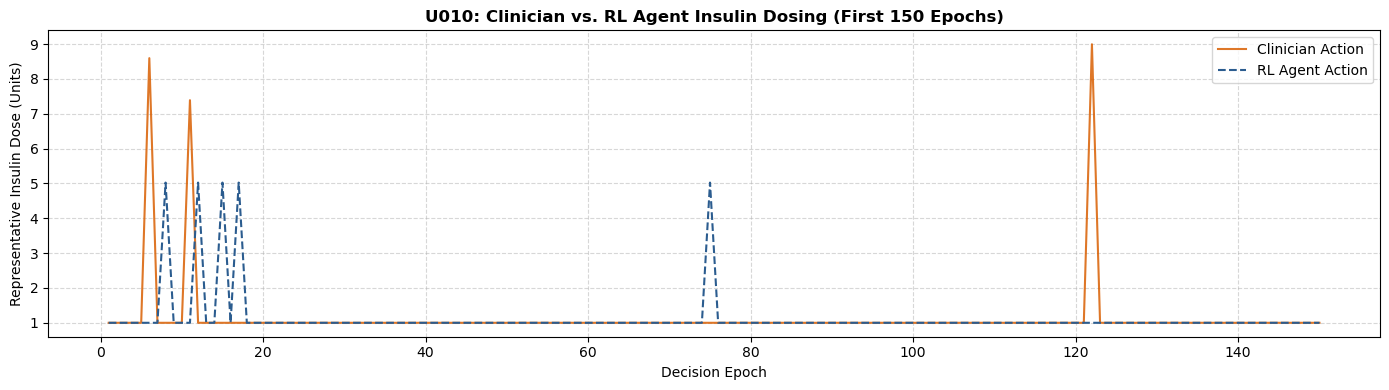

In [56]:
# Plot actual clinician insulin vs. RL suggested insulin
plt.figure(figsize=(14, 4))
plt.plot(comparison_df["Decision_Epoch"][:150], comparison_df["Clinician_Insulin"][:150], label="Clinician Action", color="#d95f02", alpha=0.85, linewidth=1.5)
plt.plot(comparison_df["Decision_Epoch"][:150], comparison_df["RL_Insulin"][:150], label="RL Agent Action", color="#2b5c8f", linestyle="--", linewidth=1.5)
plt.title("U010: Clinician vs. RL Agent Insulin Dosing (First 150 Epochs)", fontsize=12, fontweight="bold")
plt.xlabel("Decision Epoch")
plt.ylabel("Representative Insulin Dose (Units)")
plt.legend(loc="upper right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()